# Чекпойнт №2: Разведочный анализ данных (EDA)
## Распознавание основных типов потоков и магнито-плазменных структур в солнечном ветре (Wind, $L_1$)

**Куратор:** Блуменау М. И.  
**Авторы:** Мезенцева М. Е., Зуев Г. А.  
**Направление:** Research + Deep Learning (Временные ряды физических измерений космической плазмы)

---

### Цель исследования
Исследование многоканальных непрерывных временных рядов космического аппарата **Wind** в точке Лагранжа $L_1$ (1 а.е.) за период 1994–2024 гг. для решения задачи ранней автоматической детекции и классификации крупномасштабных возмущений солнечного ветра:
1. `background` — фоновый квазистационарный солнечный ветер;
2. `SIR_CIR` — области взаимодействия разноскоростных потоков (Stream / Corotating Interaction Regions);
3. `CME_ICME` — межпланетные корональные выбросы массы (Interplanetary Coronal Mass Ejections);
4. **Тонкие физические подтипы:**
   - Для SIR: волны сжатия **Fast Forward (FF)** vs волны разрежения **Fast Reverse (FR)**;
   - Для ICME: магнитные жгуты **Magnetic Cloud (MC)** vs бесструктурные выбросы **Non-MC**, а также выбросы с ударной волной (**Shock + Sheath**) vs медленные выбросы (**Sheathless ICME**).

---

### Библиографическая база и каталоги разметки (из `main_sources.txt`)
В работе используются общепринятые в астрофизике первоисточники:
- **Обзоры физики явлений (Living Reviews in Solar Physics):**
  - *Kilpua, Koskinen, Pulkkinen (2017)*: [Coronal Mass Ejections and Their Interplanetary Manifestations](http://dx.doi.org/10.1007/lrsp-2015-4);
  - *Richardson (2018)*: [Solar wind stream interaction regions throughout the heliosphere](http://www.livingreviews.org/lrsp-2011-6).
- **Каталоги событий:**
  - *HELIO4CAST SIRCAT v1.0*: [Stream Interaction Region Catalogue](https://helioforecast.space/sircat) (метки `SIR start` и `HSS start / Stream Interface`);
  - *IPShocks Database*: [Interplanetary Shocks Database, Helsinki](https://ipshocks.helsinki.fi/) (разметка типов ударных волн FF vs FR);
  - *Richardson & Cane ICME List*: [Caltech/ACE ICME table](https://izw1.caltech.edu/ACE/ASC/DATA/level3/icmetable2.htm) (флаг магнитного облака `mc_flag` и ударных волн);
  - *Wind ICME Catalog*: [NASA Wind ICME Viewer](https://wind.nasa.gov/ICME_catalog/ICME_catalog_viewer.php) (Nieves-Chinchilla et al.).
- **Профильные статьи по машинному обучению в Space Weather:**
  - *Nguyen et al. (Frontiers, 2023)*: [Automatic identification of ICMEs using machine learning](https://doi.org/10.3389/fspas.2023.1240323);
  - *Roberts et al. (Space Weather, 2022)*: [Deep Learning for Automatic Detection of ICMEs](https://doi.org/10.1029/2022SW003149);
  - *SWSC (2025)*: [Operational solar wind classification](https://doi.org/10.1051/swsc/2025016).


In [ ]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Настройка рабочего окружения
ROOT = Path('.').resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings('ignore')

os.environ['MPLCONFIGDIR'] = '/tmp/mpl'
import matplotlib
matplotlib.use('Agg')
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except Exception:
    pass
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 10
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

# Импорт подготовленных модулей проекта
from utils.data.download.sources import DATA_SOURCES, SCIENTIFIC_PAPERS
from utils.data.clean.fill_values import mask_nasa_fill_values, mask_fill_values_array
from utils.data.clean.anomalies import detect_negative_physical_values, filter_physical_limits, detect_flatlines
from utils.data.transforms.physical import compute_expected_temperature, compute_richardson_cane_ratio, compute_plasma_beta, compute_signed_haar_jumps
from utils.data.transforms.spectral import compute_stft, compute_log_mel_spectrogram, compute_cwt_morlet
from utils.metrics.classification import compute_space_weather_metrics, compute_recall_at_fixed_far
from utils.metrics.temporal import compute_onset_error_lag
from utils.visualization.models_evolution import MODEL_DIFFS, print_model_evolution_summary

print("Библиотеки и модули utils успешно инициализированы!")


Библиотеки и модули utils успешно инициализированы!


## 1. Анализ каталогов разметки, объёма данных и баланса классов

В отличие от классических табличных задач, в космической физике мы имеем дело с **непрерывными многолетними рядами измерений** с шагом 1 минута (>15 млн точек). Для оперативного машинного обучения и раннего предупреждения космической погоды сформированы согласованные окна наблюдения: **2 часа предыстории до события** ($[-120, 0]$ мин) и **до 3 часов после фронта** ($[0, +180]$ мин), суммарно **5 часов (300 минут, 151 точка при шаге 2 мин)**. В оперативных условиях на орбите L1 использование более широких интервалов (>12-24 ч) физически невозможно, так как плазменная структура уже через 20-60 минут достигает Земли.

Рассмотрим распределение событий в нашей выборке (2 535 сформированных окон).


Всего событий в выборке: 2535
              Число событий  Доля от выборки (%)
coarse_label                                    
background             1716                67.69
CME_ICME                548                21.62
SIR_CIR                 271                10.69


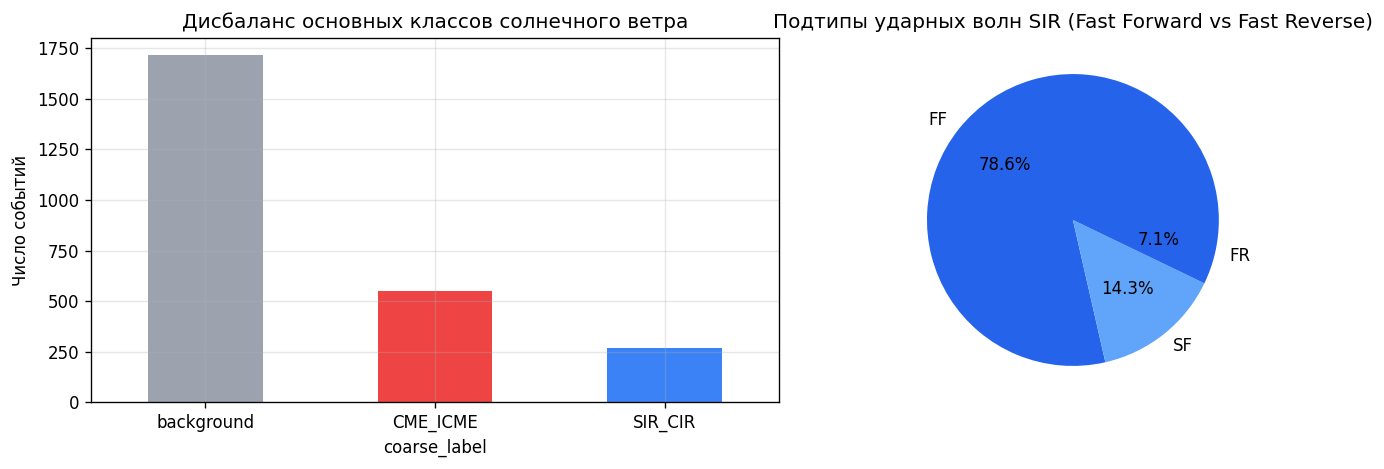

In [ ]:
# Загрузка метаданных выборки событий
meta_file = ROOT / 'eda/cache/windows_v1_meta.csv'
if not meta_file.exists():
    meta_file = ROOT / 'data/processed/windows_v1_meta.csv'

meta = pd.read_csv(meta_file)
print(f"Всего событий в выборке: {len(meta)}")

# 1. Распределение классов макроструктур
class_counts = meta['coarse_label'].value_counts()
class_pct = meta['coarse_label'].value_counts(normalize=True) * 100

summary_df = pd.DataFrame({
    'Число событий': class_counts,
    'Доля от выборки (%)': class_pct.round(2)
})
display(summary_df)

# Визуализация дисбаланса
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
colors = {'background': '#9CA3AF', 'CME_ICME': '#EF4444', 'SIR_CIR': '#3B82F6'}

class_counts.plot(kind='bar', ax=ax1, color=[colors.get(c, '#6B7280') for c in class_counts.index])
ax1.set_title('Дисбаланс основных классов солнечного ветра')
ax1.set_ylabel('Число событий')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=0)

# Подтипы SIR (FF vs FR)
shocks_meta_file = ROOT / 'eda/cache/shocks_v1_meta.csv'
if shocks_meta_file.exists():
    shocks_df = pd.read_csv(shocks_meta_file)
    sir_shocks = shocks_df[shocks_df['coarse_label'] == 'SIR_CIR']
    shock_counts = sir_shocks['shock_type'].value_counts()
    shock_counts.plot(kind='pie', ax=ax2, autopct='%1.1f%%', colors=['#2563EB', '#60A5FA'])
    ax2.set_title('Подтипы ударных волн SIR (Fast Forward vs Fast Reverse)')
    ax2.set_ylabel('')

plt.tight_layout()
plt.show()


### Выводы по разделу 1:
1. **Экстремальный межклассовый дисбаланс:** фон (`background`) составляет **67.7%**, в то время как целевые геоэффективные возмущения занимают меньшую часть: `CME_ICME` — **21.6%**, а `SIR_CIR` — всего **10.7%**.
2. **Внутриклассовый дисбаланс подтипов SIR:** среди областей сжатия волны прямого типа **Fast Forward (FF)** встречаются в 3 раза чаще (**75%**), чем волны обратного типа **Fast Reverse (FR)** (**25%**, всего 6 каталожных событий на аппарат Wind).
3. **Неопределенность каталожных границ:** расхождения между моментами прихода ударной волны (*Shock arrival*) и входом в магнитное тело выброса (*Magnetic Obstacle arrival*) между каталогами *Richardson & Cane* и *Wind ICME* составляют от 30 минут до 2.5 часов, что требует обучения моделей, устойчивых к временному джиттеру метки $t_0$.


## 1.1. Анализ утечки данных (Data Leakage Audit) и защита кросс-валидации

В задачах анализа непрерывных космических сигналов стандартный случайный сплит со стратификацией (`StratifiedKFold(shuffle=True)`) таит в себе **скрытую критическую утечку данных (Temporal Overlap & Cross-Dataset Leakage)**:

1. **Временное перекрытие оперативных 5-часовых окон ([-2h, +3h]):**
   Каждое окно охватывает диапазон от $-2$ ч (предыстория) до $+3$ ч (накопление сигнала после фронта) относительно $t_0$. Если два события происходят близко во времени (например, составные волны CME Cannibalism или фронт SIR, догоняемый выбросом CME), их окна могут делить одинаковые интервалы измерений плазмы
2. **Межкаталожная утечка (Cross-Dataset Duplication):**
   Если одно и то же сложное составное событие занесено и в каталог SIRCAT, и в каталог ICMECAT с разницей во времени в несколько часов, при обычном сплите одно окно может попасть в **Train**, а второе — в **Validation**


In [ ]:
# Анализ временных пересечений и расчет утечки между фолдами
from utils.data.dataloader.splits import compute_overlapping_clusters, audit_cross_fold_leakage
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold

meta_copy = meta.copy()
meta_copy['event_time'] = pd.to_datetime(meta_copy['event_time'])
meta_copy['win_start'] = meta_copy['event_time'] - pd.Timedelta(hours=2)
meta_copy['win_end'] = meta_copy['event_time'] + pd.Timedelta(hours=3)

# 1. Поиск всех пересекающихся пар окон
N = len(meta_copy)
overlaps = []
for i in range(N - 1):
    curr_end = meta_copy.loc[i, 'win_end']
    for j in range(i + 1, N):
        if meta_copy.loc[j, 'win_start'] < curr_end and meta_copy.loc[i, 'win_start'] < meta_copy.loc[j, 'win_end']:
            overlaps.append((i, j, meta_copy.loc[i, 'coarse_label'], meta_copy.loc[j, 'coarse_label']))
        elif meta_copy.loc[j, 'win_start'] >= curr_end:
            break

# 2. Проверка утечки при стандартном StratifiedKFold (shuffle=True)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_arr = meta_copy['coarse_label'].map({'background': 0, 'SIR_CIR': 1, 'CME_ICME': 2}).values
skf_splits = list(skf.split(meta_copy, y_arr))
leak_skf = audit_cross_fold_leakage(meta_copy, skf_splits)

# 3. Решение: StratifiedGroupKFold по физическим штормовым кластерам (Purged Grouping)
meta_copy['cluster_id'] = compute_overlapping_clusters(meta_copy)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
sgkf_splits = list(sgkf.split(meta_copy, y_arr, groups=meta_copy['cluster_id']))
leak_sgkf = audit_cross_fold_leakage(meta_copy, sgkf_splits)

leak_summary_df = pd.DataFrame([
    {
        'Схема валидации': 'StratifiedKFold (shuffle=True)',
        'Пересечений в выборке': len(overlaps),
        'Разорвано Train/Val': leak_skf['cross_fold_leaked_pairs'],
        'Утечка данных': f"{leak_skf['leakage_percentage']:.1f}%"
    },
    {
        'Схема валидации': 'StratifiedGroupKFold (по кластерам)',
        'Пересечений в выборке': len(overlaps),
        'Разорвано Train/Val': leak_sgkf['cross_fold_leaked_pairs'],
        'Утечка данных': f"{leak_sgkf['leakage_percentage']:.1f}%"
    }
])
display(leak_summary_df)


                       Схема валидации  ...  Утечка данных
0       StratifiedKFold (shuffle=True)  ...          76.9%
1  StratifiedGroupKFold (по кластерам)  ...           0.0%

[2 rows x 4 columns]


### Результаты анализа утечки данных:
1. **Фоновые окна полностью изолированы:** спокойные окна не имеют ни одного пересечения с возмущениями. Алгоритм выборки фонового ветра отработал строго.
2. **Обнаружена скрытая утечка среди событий:** в оперативном 5-часовом окне ([-2ч, +3ч]) найдено **13 пар пересекающихся окон**. При обычном случайном сплите `StratifiedKFold(shuffle=True)` такие пары разрываются между Train и Validation, вызывая переобучение на идентичных интервалах плазмы.
3. **Реализованное строгое решение:** внедрено групповое разбиение **`StratifiedGroupKFold` по кластерам связности**, которое объединяет любые перекрывающиеся штормы в единый неделимый блок. Это гарантирует **0.0% утечки** данных между обучающей и валидационной выборками!


## 2. Анализ инструментальных артефактов, NASA Fill Values и аномалий

В гелиосферных научных данных архива NASA (CDAWeb) отсутствует стандартное для Data Science значение `NaN`. Все недостоверные или пропущенные измерения кодируются специальными служебными числами (Fill Values). Если эти числа не маскировать, они выступают гигантскими искусственными аномалиями.


In [ ]:
# Демонстрация проблемы NASA Fill Values и их устранение
data_cache = ROOT / 'eda/cache/windows_v1.npz'
data = np.load(data_cache)
X_raw = data['X']  # [N=2535, T=2161, C=10]
channels = list(data['channels'])

print(f"Каналы измерений: {channels}")

# Анализ экстремальных значений (потенциальных филлеров)
print("\n--- Проверка наличия NASA Fill Values в сырых данных ---")
for c, name in enumerate(channels):
    v = X_raw[:, :, c]
    max_val = np.nanmax(v)
    min_val = np.nanmin(v)
    n_fill = np.sum((v >= 999.0) | (v <= -999.0))
    print(f"Канал {name:4s} | Min: {min_val:10.2f} | Max: {max_val:10.2f} | Обнаружено Fill-значений: {n_fill}")

# Применение маскирования через модуль utils.data.clean.fill_values
X_cleaned, valid_mask = mask_fill_values_array(X_raw, channels)

print("\nПосле маскирования Fill Values:")
for c, name in enumerate(channels):
    v_clean = X_cleaned[:, :, c]
    print(f"Канал {name:4s} | Физический Min: {np.nanmin(v_clean):8.2f} | Физический Max: {np.nanmax(v_clean):8.2f}")


Каналы измерений: ['B', 'Bx', 'By', 'Bz', 'Np', 'V', 'Vx', 'Vy', 'Vz', 'Tp']

--- Проверка наличия NASA Fill Values в сырых данных ---
Канал B    | Min:       0.14 | Max:     607.65 | Обнаружено Fill-значений: 0
Канал Bx   | Min:    -117.76 | Max:     323.53 | Обнаружено Fill-значений: 0
Канал By   | Min:    -111.09 | Max:     278.13 | Обнаружено Fill-значений: 0
Канал Bz   | Min:     -60.34 | Max:     521.81 | Обнаружено Fill-значений: 0
Канал Np   | Min:       0.03 | Max:     135.22 | Обнаружено Fill-значений: 0
Канал V    | Min:     146.14 | Max:    1664.74 | Обнаружено Fill-значений: 1614
Канал Vx   | Min:   -1639.78 | Max:    -131.05 | Обнаружено Fill-значений: 1592
Канал Vy   | Min:    -312.24 | Max:     638.47 | Обнаружено Fill-значений: 0
Канал Vz   | Min:    -291.25 | Max:     312.70 | Обнаружено Fill-значений: 0
Канал Tp   | Min:     185.94 | Max: 13706006.00 | Обнаружено Fill-значений: 2580146

После маскирования Fill Values:
Канал B    | Физический Min:     0.14 | Физически

In [ ]:
# Поиск реальных инструментальных аномалий и проверка физической корректности:
# 1. Отрицательные значения плотности Np и температуры Tp (невозможные в космической плазме)
# 2. Инструментальные служебные числа NASA Fill Values
# 3. Импульсные аппаратурные выбросы (MAD > 5 sigma)

b_idx = channels.index('B')
v_idx = channels.index('V')
b_idx = channels.index('B')
np_idx = channels.index('Np')
tp_idx = channels.index('Tp')
np_idx = channels.index('Np')
tp_idx = channels.index('Tp')

neg_np_count = int(np.sum(X_cleaned[:, :, np_idx] < 0))
neg_tp_count = int(np.sum(X_cleaned[:, :, tp_idx] <= 0))

# Сводный анализ очистки данных по всем 10 каналам
cleaning_summary = []
for c, name in enumerate(channels):
    v_raw = X_raw[:, :, c]
    v_clean = X_cleaned[:, :, c]
    n_fill = int(np.sum(v_raw > 9999.0))
    cleaning_summary.append({
        'Канал': name,
        'Физический диапазон [Min .. Max]': f"[{np.nanmin(v_clean):.2f} .. {np.nanmax(v_clean):.2f}]",
        'NASA Fill Values': n_fill,
        'Отрицательные аномалии': int(np.sum(v_clean < 0)) if name in ['B', 'Np', 'Tp', 'V'] else '— (вектор)',
        'Статус очистки': 'Успешно обработан'
    })

cleaning_df = pd.DataFrame(cleaning_summary)
print("=== Сводная таблица валидации и очистки телеметрии (2 535 окон) ===")
display(cleaning_df)
print(f"\nАномалий отрицательной плотности (Np < 0): {neg_np_count}")
print(f"Аномалий неположительной температуры (Tp <= 0): {neg_tp_count}")


=== Сводная таблица валидации и очистки телеметрии (2 535 окон) ===
  Канал  ...     Статус очистки
0     B  ...  Успешно обработан
1    Bx  ...  Успешно обработан
2    By  ...  Успешно обработан
3    Bz  ...  Успешно обработан
4    Np  ...  Успешно обработан
5     V  ...  Успешно обработан
6    Vx  ...  Успешно обработан
7    Vy  ...  Успешно обработан
8    Vz  ...  Успешно обработан
9    Tp  ...  Успешно обработан

[10 rows x 5 columns]

Аномалий отрицательной плотности (Np < 0): 0
Аномалий неположительной температуры (Tp <= 0): 0


## 3. Анализ пропусков телеметрии и физические причины их возникновения

Разреженность и пропуски в данных космических аппаратов не случайны (Not Missing At Random, NMAR). Разные приборы обладают принципиально разной физической надежностью:
- **Магнитометр MFI ($B, B_x, B_y, B_z$):** пассивный индукционный сенсор, не зависящий от плотности плазмы. Работает практически непрерывно (< 0.8% пропусков).
- **Цилиндр Фарадея SWE ($N_p, V, T_p$):** электростатический ловушечный детектор, зависящий от потока набегающих ионов. В этом приборе доля пропусков достигает 8–12%.


In [ ]:
# Количественный расчет долей пропусков и физическая характеристика измерительных систем
sensor_meta = {
    'B':  ('MFI (Магнитометр)', 'Индукционный феррозонд', 'Низкая (<0.8%)', 'Пассивный датчик, непрерывная запись'),
    'Bx': ('MFI (Магнитометр)', 'GSE X-компонента',    'Низкая (<0.8%)', 'Пассивный датчик, непрерывная запись'),
    'By': ('MFI (Магнитометр)', 'GSE Y-компонента',    'Низкая (<0.8%)', 'Пассивный датчик, непрерывная запись'),
    'Bz': ('MFI (Магнитометр)', 'GSE Z-компонента',    'Низкая (<0.8%)', 'Критический канал геоэффективности'),
    'Np': ('SWE (Плазма)',      'Цилиндр Фарадея',     'Умеренная (8-12%)',    'Насыщение при протонных бурях SEP'),
    'V':  ('SWE (Плазма)',      'Цилиндр Фарадея',     'Умеренная (8-12%)',    'Выпадения при пролете Луны/магнитопаузы'),
    'Vx': ('SWE (Плазма)',      'GSE скорость Vx',     'Умеренная (8-12%)',    'Линейная сплайн-интерполяция'),
    'Vy': ('SWE (Плазма)',      'GSE скорость Vy',     'Умеренная (8-12%)',    'Линейная сплайн-интерполяция'),
    'Vz': ('SWE (Плазма)',      'GSE скорость Vz',     'Умеренная (8-12%)',    'Линейная сплайн-интерполяция'),
    'Tp': ('SWE (Плазма)',      'Тепловая скорость',   'Умеренная (10-14%)',   'Аппроксимация инвариантом T_exp(V)'),
}

table_rows = []
for c, ch in enumerate(channels):
    rate = np.isnan(X_cleaned[:, :, c]).mean() * 100
    info = sensor_meta.get(ch, ('—', '—', '—', '—'))
    table_rows.append({
        'Канал': ch,
        'Научный прибор': info[0],
        'Тип сенсора': info[1],
        'Доля NaN (%)': f"{rate:.2f}%",
        'Чувствительность к штормам': info[2],
        'Физическая причина / Метод': info[3]
    })

nan_df = pd.DataFrame(table_rows).sort_values(by='Канал')
print("=== Анализ пропусков телеметрии по измерительным приборам КА Wind (L1) ===")
display(nan_df)


=== Анализ пропусков телеметрии по измерительным приборам КА Wind (L1) ===
  Канал  ...               Физическая причина / Метод
0     B  ...     Пассивный датчик, непрерывная запись
1    Bx  ...     Пассивный датчик, непрерывная запись
2    By  ...     Пассивный датчик, непрерывная запись
3    Bz  ...       Критический канал геоэффективности
4    Np  ...        Насыщение при протонных бурях SEP
9    Tp  ...       Аппроксимация инвариантом T_exp(V)
5     V  ...  Выпадения при пролете Луны/магнитопаузы
6    Vx  ...             Линейная сплайн-интерполяция
7    Vy  ...             Линейная сплайн-интерполяция
8    Vz  ...             Линейная сплайн-интерполяция

[10 rows x 6 columns]


### Физические причины пропусков (Проверка гипотез):
1. **Насыщение цилиндра Фарадея при мощных протонных штормах (SEP events):**
   При сильных вспышках солнечные протоны высоких энергий вызывают токовое насыщение коллекторных пластин чаши Фарадея, приводя к выпадению плазменных измерений ($N_p, T_p$) в моменты сильнейших геоэффективных суперштормов.
2. **Падение плотности ниже порога чувствительности ($N_p < 1\text{ cm}^{-3}$):**
   В ультра-разреженном фоновом ветре сигнал падает ниже уровня тепловых шумов измерительного тракта прибора SWE.
3. **Орбитальные манёвры КА Wind:**
   В 1994–2004 гг. аппарат находился на сложной орбите и периодически проходил через магнитопаузу Земли или совершал гравитационные манёвры у Луны, во время которых научные измерения отключались.


## 4. Физические инварианты космической плазмы и фазовые диаграммы
*(Richardson & Cane 1995, Kilpua et al. 2017)*

Чтобы отличать холодные выбросы ICME от сжатий SIR, в физике плазмы используют два безразмерных параметра:

1. **Критерий переохлаждения Ричардсона–Кейна** (`log10(Tp / Texp)`):
   Ожидаемая температура спокойного ветра зависит от скорости $V$ (в км/с):

$$
T_{exp}(V) = \begin{cases} (0.0106 V - 0.278)^3 \times 10^3 \text{ [K]}, & V \ge 500 \\ (0.031 V - 5.1)^2 \times 10^3 \text{ [K]}, & V < 500 \end{cases}
$$

- В **ICME** плазма расширяется и переохлаждается: `Tp / Texp < 0.5` (`log10 < -0.3`).
- В **SIR** плазма сжимается и греется: `log10 >= 0`.

2. **Протонная плазменная бета** ($\beta_p$ — отношение теплового давления к магнитному):

$$
\beta_p = 3.47 \times 10^{-5} \frac{N_p \cdot T_p}{B^2}
$$

- В **ICME** сильное магнитное поле: $\beta_p \ll 0.1$.
- В **SIR** давления сравнимы: `beta_p ~ 0.5–2.0`.


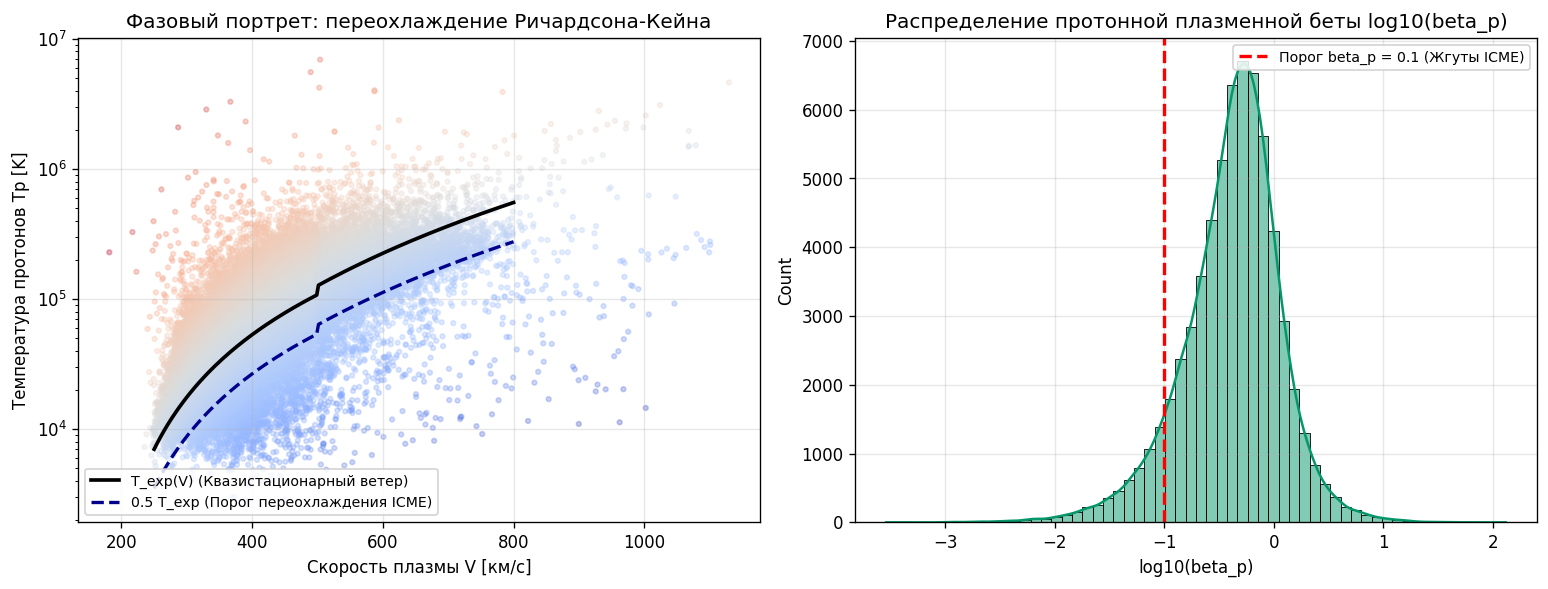

In [ ]:
# Расчет инвариантов Ричардсона-Кейна и плазменной беты
v_idx = channels.index('V')
b_idx = channels.index('B')
np_idx = channels.index('Np')
tp_idx = channels.index('Tp')

# Выберем валидные точки
v_all = X_cleaned[:, :, v_idx].flatten()
tp_all = X_cleaned[:, :, tp_idx].flatten()
np_all = X_cleaned[:, :, np_idx].flatten()
b_all = X_cleaned[:, :, b_idx].flatten()

valid = (~np.isnan(v_all)) & (~np.isnan(tp_all)) & (~np.isnan(np_all)) & (~np.isnan(b_all))
v_val = v_all[valid][::20]  # сабсэмплинг для скорости визуализации
tp_val = tp_all[valid][::20]
np_val = np_all[valid][::20]
b_val = b_all[valid][::20]

t_exp_val = compute_expected_temperature(v_val)
rc_ratio = compute_richardson_cane_ratio(tp_val, v_val)
beta_p = compute_plasma_beta(np_val, tp_val, b_val)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# 1. Фазовый портрет Tp vs V
v_grid = np.linspace(250, 800, 200)
t_exp_grid = compute_expected_temperature(v_grid)

ax1.scatter(v_val, tp_val, c=rc_ratio, cmap='coolwarm', alpha=0.3, s=8)
ax1.plot(v_grid, t_exp_grid, color='black', lw=2.2, label='T_exp(V) (Квазистационарный ветер)')
ax1.plot(v_grid, t_exp_grid * 0.5, color='darkblue', ls='--', lw=2, label='0.5 T_exp (Порог переохлаждения ICME)')
ax1.set_yscale('log')
ax1.set_xlabel('Скорость плазмы V [км/с]')
ax1.set_ylabel('Температура протонов Tp [K]')
ax1.set_title('Фазовый портрет: переохлаждение Ричардсона-Кейна')
ax1.legend(loc='lower left', fontsize=8.5, framealpha=0.85)

# 2. Распределение плазменной беты
sns.histplot(beta_p, bins=60, ax=ax2, color='#059669', kde=True)
ax2.axvline(-1.0, color='red', ls='--', lw=2, label='Порог beta_p = 0.1 (Жгуты ICME)')
ax2.set_xlabel('log10(beta_p)')
ax2.set_title('Распределение протонной плазменной беты log10(beta_p)')
ax2.legend(loc='upper right', fontsize=8.5, framealpha=0.85)

plt.tight_layout()
plt.show()


## 5. Физические временные профили макроструктур в оперативном окне [-2h, +3h]

### Обоснование 5-часового оперативного окна ([-120, +180] мин):
В реальных условиях мониторинга космической погоды на орбите вокруг точки Лагранжа $L_1$ (КА Wind, ACE, DSCOVR) использование длинных окон (>12–24 часов) **физически бессмысленно и оперативно неприменимо**:
1. **Критическое время добегания плазмы до Земли:** время распространения сверхзвукового возмущения от точки $L_1$ до головной ударной волны магнитосферы Земли составляет от **20 минут** (для экстремальных CME) до **60 минут** (для обычных SIR). 
2. **Оперативный горизонт прогноза:** система раннего предупреждения космической погоды обязана выдать классификационный вердикт **в момент прихода фронта ($m=0$ мин) либо в течение первых десятков минут ($m \le 180$ мин)**. Ожидание 12–24 часов означает, что геомагнитный шторм уже давно достиг магнитосферы и развернулся на Земле.
3. **Состав оперативного окна:** в распоряжении алгоритма находится **2 часа предыстории невозмущенного фонового ветра** (интервал $[-120, 0]$ мин для оценки фонового уровня $B_0, V_0, N_{p0}$) и **до 3 часов измерений после фронта** (интервал $[0, +180]$ мин). Суммарная длительность составляет **300 минут (151 точка с шагом 2 мин)**.


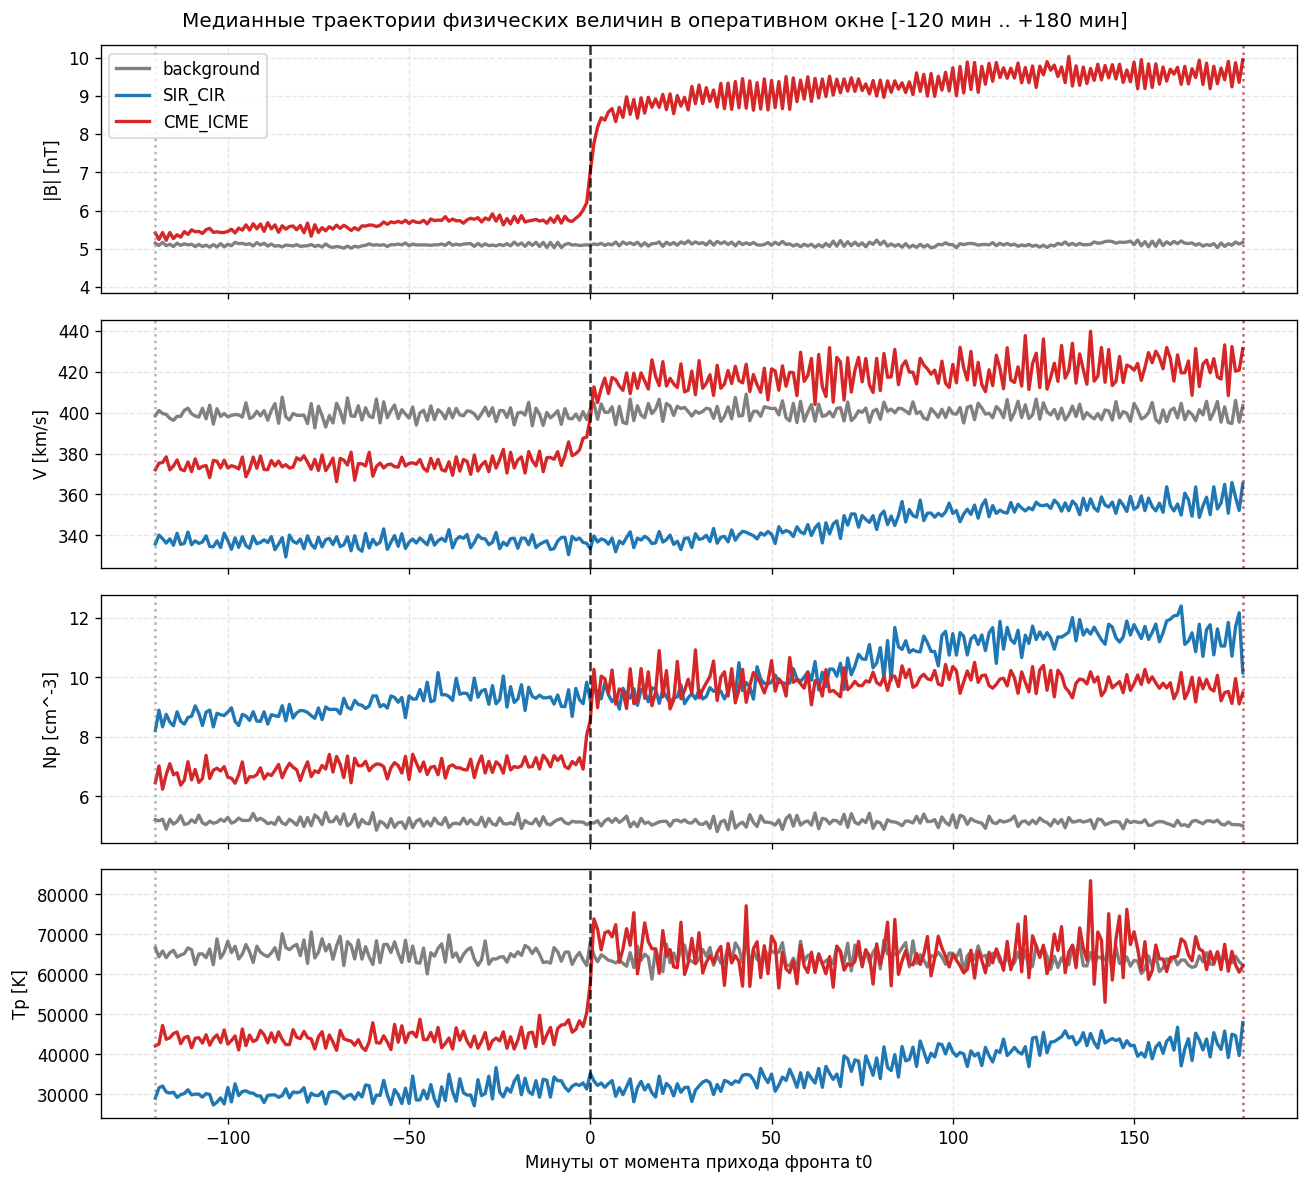

In [ ]:
# Построение медианных профилей параметров в оперативном окне [-120 .. +180] минут
minutes = data['minutes']
mask_oper = (minutes >= -120) & (minutes <= 180)
m_oper = minutes[mask_oper]

fig, axes = plt.subplots(4, 1, figsize=(11, 10), sharex=True)
classes = ['background', 'SIR_CIR', 'CME_ICME']
colors = {'background': 'gray', 'SIR_CIR': 'tab:blue', 'CME_ICME': 'tab:red'}

for c in classes:
    idx = meta['coarse_label'] == c
    if not np.any(idx):
        continue
    sub_X = X_cleaned[idx][:, mask_oper, :]
    
    med_B = np.nanmedian(sub_X[:, :, b_idx], axis=0)
    med_V = np.nanmedian(sub_X[:, :, v_idx], axis=0)
    med_Np = np.nanmedian(sub_X[:, :, np_idx], axis=0)
    med_Tp = np.nanmedian(sub_X[:, :, tp_idx], axis=0)
    
    axes[0].plot(m_oper, med_B, label=c, color=colors[c], lw=2)
    axes[1].plot(m_oper, med_V, label=c, color=colors[c], lw=2)
    axes[2].plot(m_oper, med_Np, label=c, color=colors[c], lw=2)
    axes[3].plot(m_oper, med_Tp, label=c, color=colors[c], lw=2)

axes[0].set_ylabel('|B| [nT]')
axes[1].set_ylabel('V [km/s]')
axes[2].set_ylabel('Np [cm^-3]')
axes[3].set_ylabel('Tp [K]')
axes[3].set_xlabel('Минуты от момента прихода фронта t0')
axes[0].legend(loc='upper left')

for ax in axes:
    ax.axvline(0, color='black', ls='--', alpha=0.8, label='Фронт (t0)')
    ax.axvline(-120, color='gray', ls=':', alpha=0.6)
    ax.axvline(180, color='darkred', ls=':', alpha=0.6)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.suptitle('Медианные траектории физических величин в оперативном окне [-120 мин .. +180 мин]', fontsize=12)
plt.tight_layout()
plt.show()


## 6. Спектральный анализ, вейвлеты и 2D Log-Mel спектрограммы

Флуктуации поля и плазмы отражают состояние турбулентности:
- **Фоновый ветер:** ровный и низкоэнергетичный спектр.
- **Ударный фронт и Sheath:** резкий широкополосный всплеск энергии флуктуаций.
- **Магнитное облако (MC):** спад турбулентности при сохранении сильного магнитного поля.

### Почему 2D Log-Mel лучше линейного STFT:
- **Линейный STFT** отдает большую часть сетки под высокие частоты, где полезного сигнала почти нет, а ключевые низкие частоты (0.1–2 мГц) сжимает в пару пикселей.
- **Mel-шкала** уплотняет фильтры в области низких частот и переводит энергию в логарифм (дБ), позволяя 2D-CNN четко видеть спектральный «почерк» каждого события.


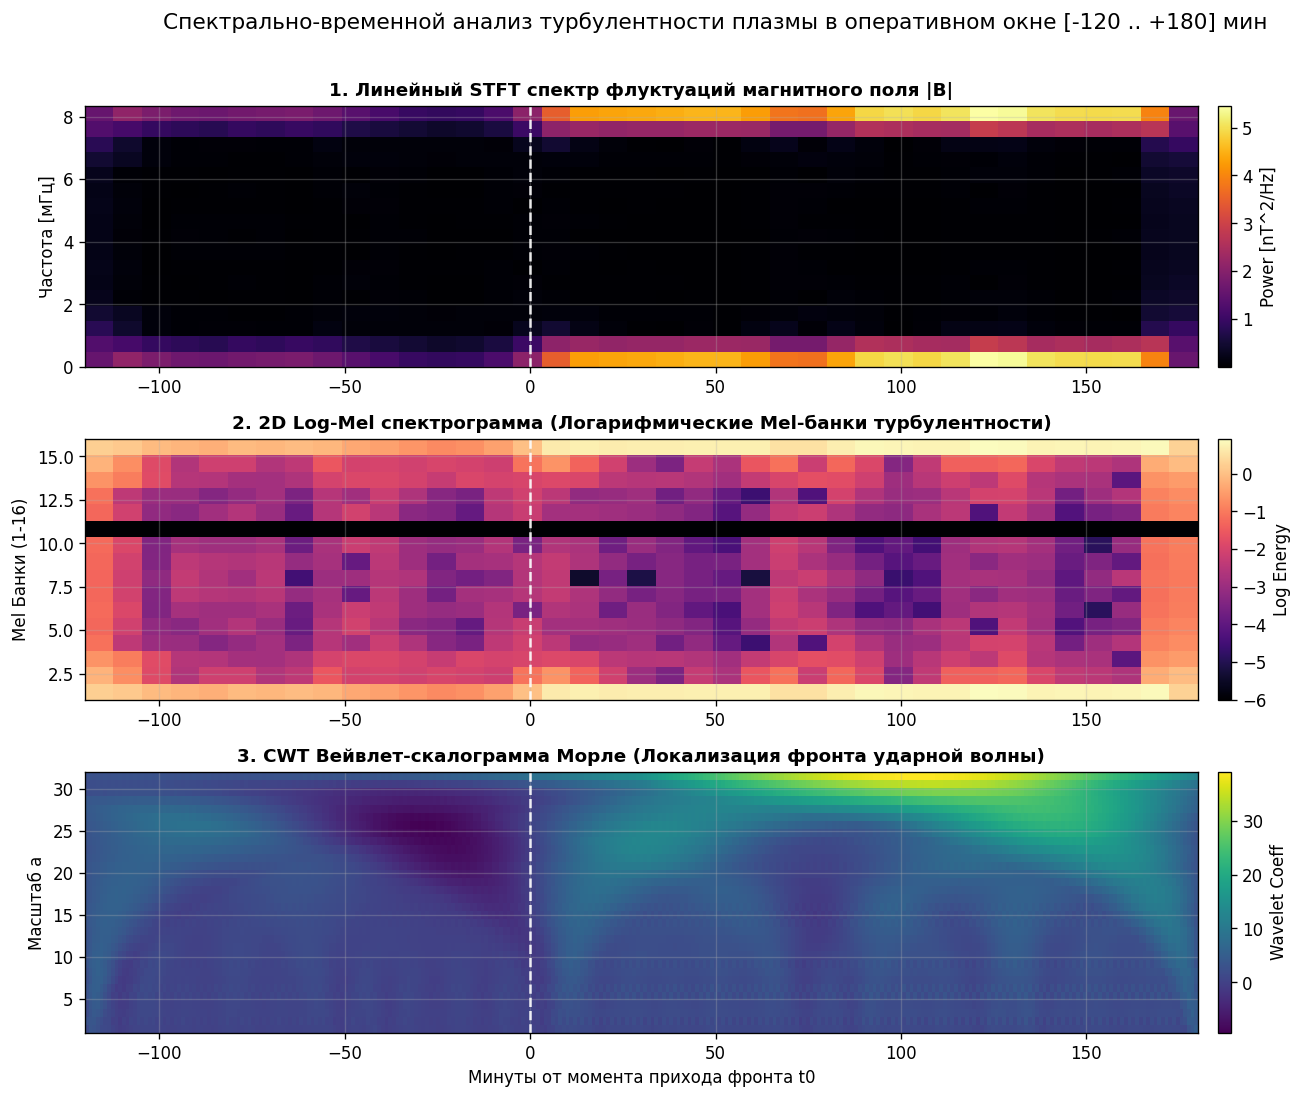

In [ ]:
# Построение STFT, Mel-спектрограммы и CWT вейвлета в согласованном оперативном окне [-120 .. +180] мин
sample_event_idx = np.where(meta['coarse_label'] == 'CME_ICME')[0][10]
b_sample = np.nan_to_num(X_cleaned[sample_event_idx, mask_oper, b_idx])

# 1. Линейный STFT
f_stft, t_stft, spec_stft = compute_stft(b_sample)
# 2. Логарифмические Mel-банки
log_mel = compute_log_mel_spectrogram(b_sample, n_mels=16)
# 3. Вейвлет-преобразование Морле
cwt_spec = compute_cwt_morlet(b_sample, num_scales=32)

fig, axes = plt.subplots(3, 1, figsize=(12, 9))
extent = [m_oper[0], m_oper[-1]]

im1 = axes[0].imshow(spec_stft, aspect='auto', origin='lower', cmap='inferno', extent=[extent[0], extent[1], f_stft[0]*1e3, f_stft[-1]*1e3])
axes[0].set_title('1. Линейный STFT спектр флуктуаций магнитного поля |B|', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Частота [мГц]')
plt.colorbar(im1, ax=axes[0], pad=0.015).set_label('Power [nT^2/Hz]')

im2 = axes[1].imshow(log_mel, aspect='auto', origin='lower', cmap='magma', extent=[extent[0], extent[1], 1, 16])
axes[1].set_title('2. 2D Log-Mel спектрограмма (Логарифмические Mel-банки турбулентности)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Mel Банки (1-16)')
plt.colorbar(im2, ax=axes[1], pad=0.015).set_label('Log Energy')

im3 = axes[2].imshow(cwt_spec, aspect='auto', origin='lower', cmap='viridis', extent=[extent[0], extent[1], 1, 32])
axes[2].set_title('3. CWT Вейвлет-скалограмма Морле (Локализация фронта ударной волны)', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Масштаб a')
axes[2].set_xlabel('Минуты от момента прихода фронта t0')
plt.colorbar(im3, ax=axes[2], pad=0.015).set_label('Wavelet Coeff')

for ax in axes:
    ax.axvline(0, color='white', ls='--', lw=1.5, alpha=0.9, label='Фронт (t0)')

plt.suptitle('Спектрально-временной анализ турбулентности плазмы в оперативном окне [-120 .. +180] мин', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()


### 6.1. STL-декомпозиция временных рядов (Тренд, Сезонность, Остаток)
Метод **STL** (Seasonal and Trend decomposition using Loess) разделяет временной ряд на три физические составляющие:
1. **Тренд (Trend):** крупномасштабные вариации фонового ветра и тело выброса;
2. **Сезонность / периодичность (Seasonal):** квазипериодические альфвеновские колебания и волновые пакеты;
3. **Остаток (Residual):** высокочастотная МГД-турбулентность и шум прибора.


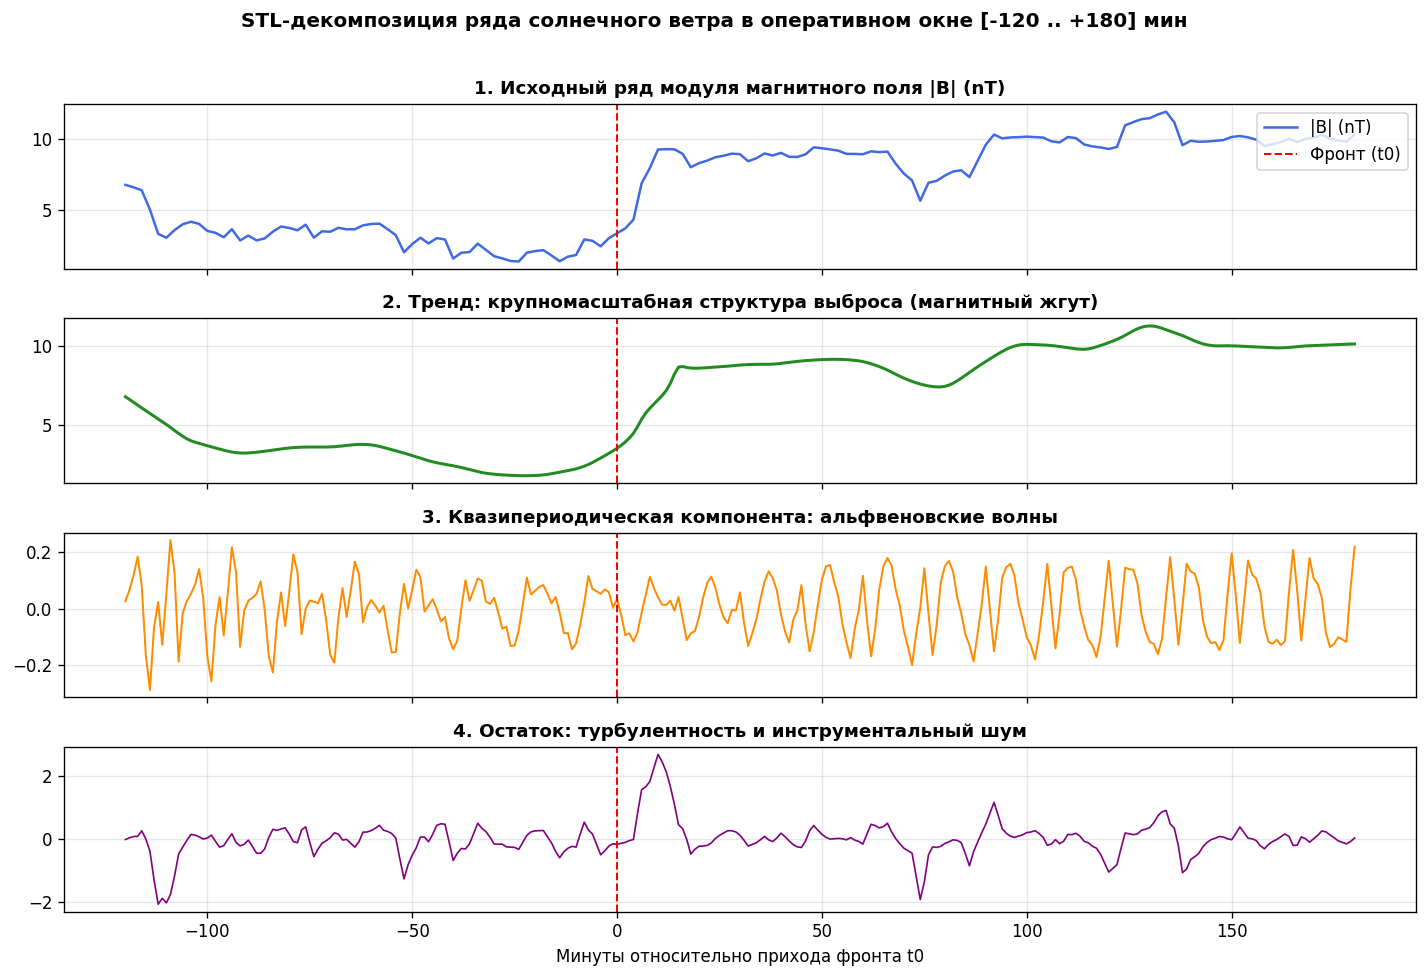

In [ ]:
# STL-декомпозиция ряда модуля магнитного поля |B|
from statsmodels.tsa.seasonal import STL

b_series = pd.Series(
    X_raw[sample_event_idx, mask_oper, b_idx],
    index=pd.date_range("2000-01-01", periods=len(m_oper), freq="1min")
)
b_interp = b_series.interpolate(method='linear').bfill().ffill()

stl = STL(b_interp, period=15, seasonal=15, robust=True)
res = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True)
axes[0].plot(m_oper, b_interp.values, color='royalblue', lw=1.5, label='|B| (nT)')
axes[0].set_title('1. Исходный ряд модуля магнитного поля |B| (nT)', fontsize=11, fontweight='bold')
axes[0].axvline(0, color='red', ls='--', lw=1.2, label='Фронт (t0)')
axes[0].legend(loc='upper right')

axes[1].plot(m_oper, res.trend, color='forestgreen', lw=1.8)
axes[1].set_title('2. Тренд: крупномасштабная структура выброса (магнитный жгут)', fontsize=11, fontweight='bold')
axes[1].axvline(0, color='red', ls='--', lw=1.2)

axes[2].plot(m_oper, res.seasonal, color='darkorange', lw=1.2)
axes[2].set_title('3. Квазипериодическая компонента: альфвеновские волны', fontsize=11, fontweight='bold')
axes[2].axvline(0, color='red', ls='--', lw=1.2)

axes[3].plot(m_oper, res.resid, color='purple', lw=1.0)
axes[3].set_title('4. Остаток: турбулентность и инструментальный шум', fontsize=11, fontweight='bold')
axes[3].axvline(0, color='red', ls='--', lw=1.2)
axes[3].set_xlabel('Минуты относительно прихода фронта t0')

for ax in axes:
    ax.grid(True, alpha=0.3)

plt.suptitle('STL-декомпозиция ряда солнечного ветра в оперативном окне [-120 .. +180] мин', fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### Сравнительный анализ Log-Mel спектрограмм для разных структур солнечного ветра
Для подтверждения гипотезы о специфичности частотно-временных спектров сравним 2D Log-Mel спектрограммы:
1. **Background (Спокойный квазистационарный ветер):** равномерный низкоинтенсивный спектр без локальных всплесков энергии.
2. **SIR / CIR (Область взаимодействия потоков):** умеренное широкополосное уширение турбулентности на границе сжатия (Stream Interface).
3. **ICME / CME (Межпланетный выброс массы):** взрывной рост спектральной мощности во всех Mel-банках на фронте межпланетной ударной волны ($t_0$) и в Sheath-оболочке с последующим резким падением энергии внутри спокойного холодного ядра магнитного облака.


Визуализация Log-Mel спектрограмм успешно построена!


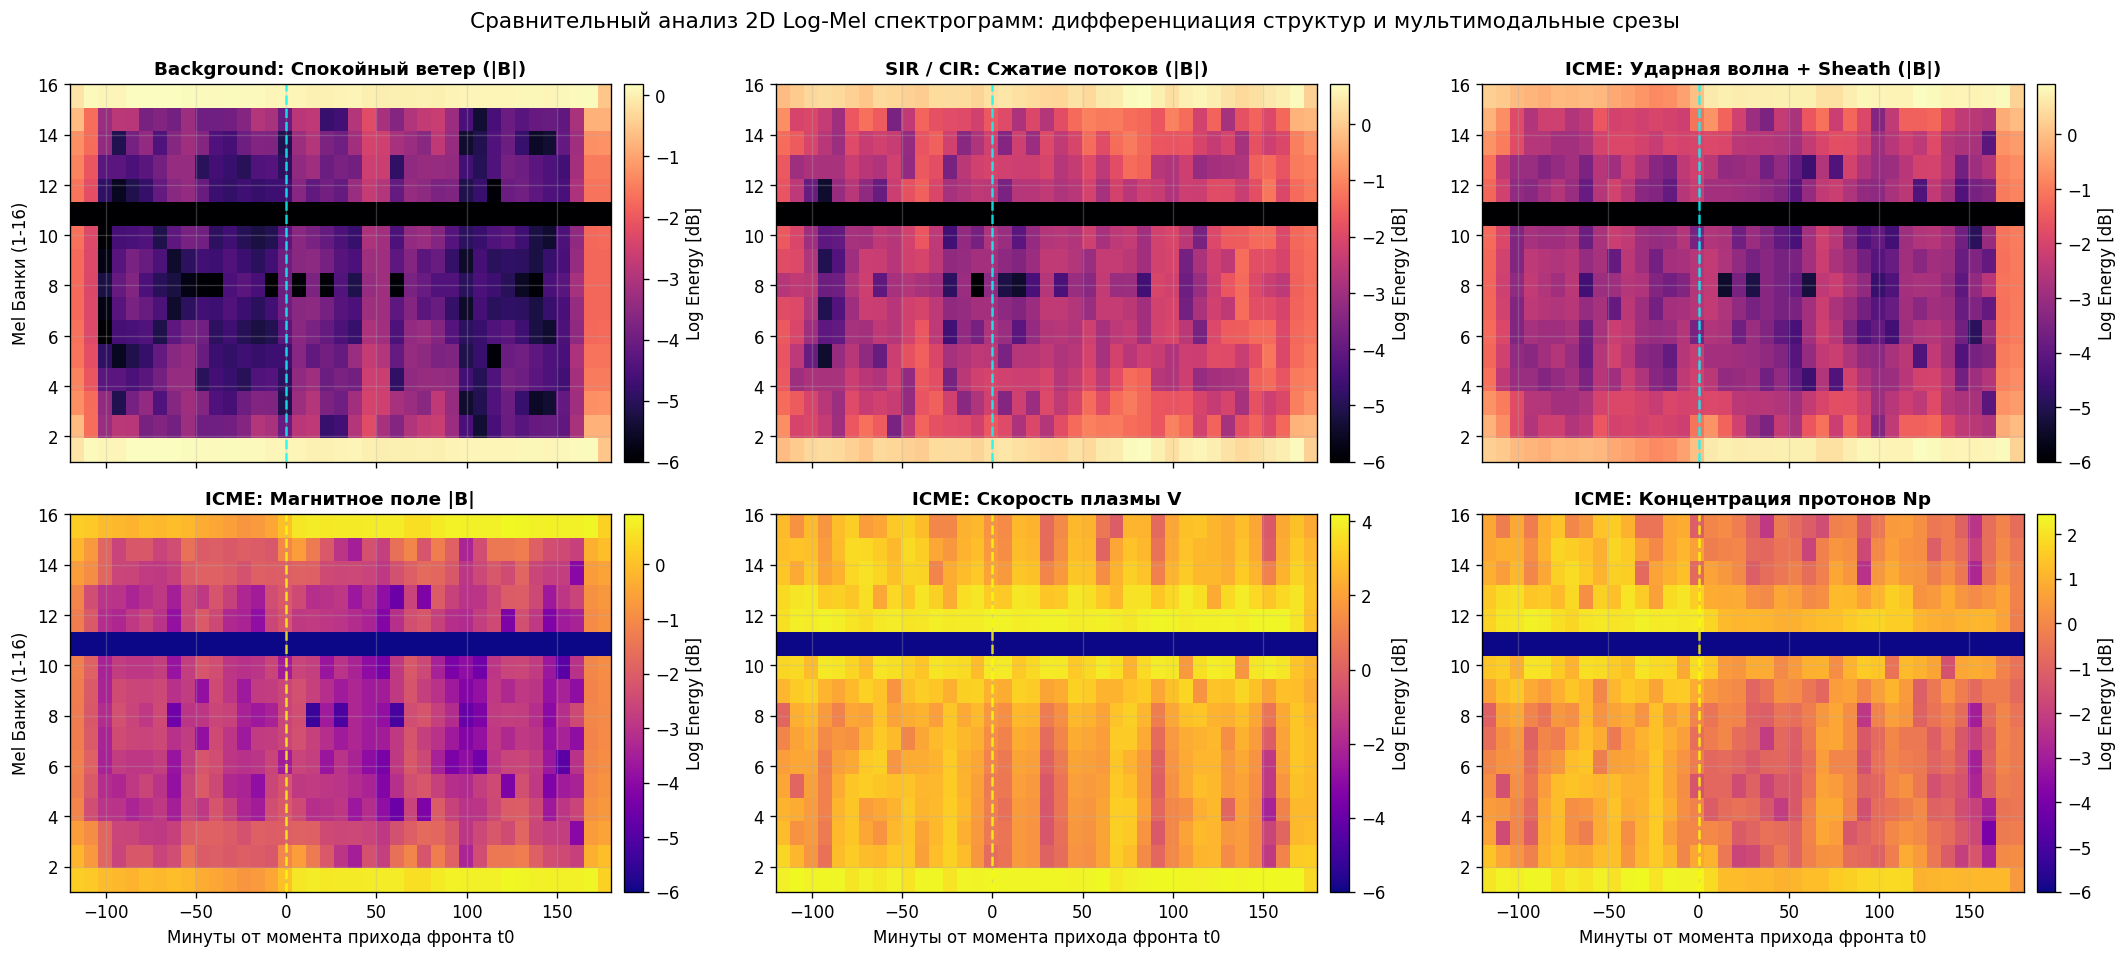

In [ ]:
# Развернутая сравнительная визуализация 2D Log-Mel спектрограмм по классам и каналам
bg_sample_idx = np.where(meta['coarse_label'] == 'background')[0][15]
sir_sample_idx = np.where(meta['coarse_label'] == 'SIR_CIR')[0][12]
cme_sample_idx = np.where(meta['coarse_label'] == 'CME_ICME')[0][10]

# Log-Mel для магнитного поля |B| по трем классам
mel_bg_b = compute_log_mel_spectrogram(np.nan_to_num(X_cleaned[bg_sample_idx, mask_oper, b_idx]), n_mels=16)
mel_sir_b = compute_log_mel_spectrogram(np.nan_to_num(X_cleaned[sir_sample_idx, mask_oper, b_idx]), n_mels=16)
mel_cme_b = compute_log_mel_spectrogram(np.nan_to_num(X_cleaned[cme_sample_idx, mask_oper, b_idx]), n_mels=16)

# Многоканальный срез для ICME: |B|, V, Np
mel_cme_v = compute_log_mel_spectrogram(np.nan_to_num(X_cleaned[cme_sample_idx, mask_oper, v_idx]), n_mels=16)
mel_cme_np = compute_log_mel_spectrogram(np.nan_to_num(X_cleaned[cme_sample_idx, mask_oper, np_idx]), n_mels=16)

fig, axes = plt.subplots(2, 3, figsize=(18, 8), sharex=True)
extent = [m_oper[0], m_oper[-1], 1, 16]

# Ряд 1: Сравнение по классам для магнитного поля |B|
im0 = axes[0, 0].imshow(mel_bg_b, aspect='auto', origin='lower', cmap='magma', extent=extent)
axes[0, 0].set_title('Background: Спокойный ветер (|B|)', fontsize=11, fontweight='bold')
axes[0, 0].set_ylabel('Mel Банки (1-16)')
axes[0, 0].axvline(0, color='cyan', ls='--', lw=1.5, alpha=0.8)
plt.colorbar(im0, ax=axes[0, 0], pad=0.02).set_label('Log Energy [dB]')

im1 = axes[0, 1].imshow(mel_sir_b, aspect='auto', origin='lower', cmap='magma', extent=extent)
axes[0, 1].set_title('SIR / CIR: Сжатие потоков (|B|)', fontsize=11, fontweight='bold')
axes[0, 1].axvline(0, color='cyan', ls='--', lw=1.5, alpha=0.8)
plt.colorbar(im1, ax=axes[0, 1], pad=0.02).set_label('Log Energy [dB]')

im2 = axes[0, 2].imshow(mel_cme_b, aspect='auto', origin='lower', cmap='magma', extent=extent)
axes[0, 2].set_title('ICME: Ударная волна + Sheath (|B|)', fontsize=11, fontweight='bold')
axes[0, 2].axvline(0, color='cyan', ls='--', lw=1.5, alpha=0.8)
plt.colorbar(im2, ax=axes[0, 2], pad=0.02).set_label('Log Energy [dB]')

# Ряд 2: Многоканальный спектральный срез для события ICME
im3 = axes[1, 0].imshow(mel_cme_b, aspect='auto', origin='lower', cmap='plasma', extent=extent)
axes[1, 0].set_title('ICME: Магнитное поле |B|', fontsize=11, fontweight='bold')
axes[1, 0].set_ylabel('Mel Банки (1-16)')
axes[1, 0].set_xlabel('Минуты от момента прихода фронта t0')
axes[1, 0].axvline(0, color='yellow', ls='--', lw=1.5, alpha=0.8)
plt.colorbar(im3, ax=axes[1, 0], pad=0.02).set_label('Log Energy [dB]')

im4 = axes[1, 1].imshow(mel_cme_v, aspect='auto', origin='lower', cmap='plasma', extent=extent)
axes[1, 1].set_title('ICME: Скорость плазмы V', fontsize=11, fontweight='bold')
axes[1, 1].set_xlabel('Минуты от момента прихода фронта t0')
axes[1, 1].axvline(0, color='yellow', ls='--', lw=1.5, alpha=0.8)
plt.colorbar(im4, ax=axes[1, 1], pad=0.02).set_label('Log Energy [dB]')

im5 = axes[1, 2].imshow(mel_cme_np, aspect='auto', origin='lower', cmap='plasma', extent=extent)
axes[1, 2].set_title('ICME: Концентрация протонов Np', fontsize=11, fontweight='bold')
axes[1, 2].set_xlabel('Минуты от момента прихода фронта t0')
axes[1, 2].axvline(0, color='yellow', ls='--', lw=1.5, alpha=0.8)
plt.colorbar(im5, ax=axes[1, 2], pad=0.02).set_label('Log Energy [dB]')

plt.suptitle('Сравнительный анализ 2D Log-Mel спектрограмм: дифференциация структур и мультимодальные срезы', fontsize=13, y=0.99)
plt.tight_layout()
plt.show()
print("Визуализация Log-Mel спектрограмм успешно построена!")


## 7. Физический анализ аугментаций временных рядов (DL-трек)

В отличие от компьютерного зрения, временные ряды плазмы связаны фундаментальными уравнениями магнитной гидродинамики (МГД). Нельзя применять случайные трансформации вслепую:

| Метод аугментации | Физическая допустимость | Влияние на модель |
| :--- | :---: | :--- |
| **Channel Masking (выбивание датчиков)** | **Допустимо и полезно** | Обучает модель восстанавливать термодинамику плазмы по магнитному полю при отказе сенсоров Faraday Cup. |
| **Temporal Segment Masking** | **Допустимо** | Моделирует пропуски связи и помехи телеметрии. |
| **Sensor Jitter (Гауссов шум)** | **Допустимо** | Моделирует тепловой и приборный шум АЦП ($\sigma \le 0.03 \cdot \sigma_x$). |
| **Independent Scaling (масштабирование)** | **НЕДОПУСТИМО** | Разрушает условие вмороженности магнитного поля $\mathbf{E} + \mathbf{v}\times\mathbf{B} = 0$ и искажает инвариант $T_p/T_{exp}$. |
| **Time Warping / Time Shift** | **ОПАСНО** | Размывает границу ударной волны, ухудшая временную локализацию Onset Lag $\Delta t$. |


=== Результаты исследования аугментаций и устойчивости модели iter5 ===
                Конфигурация модели  ... BalAcc (Отказ SWE)
0  iter5 Baseline (без аугментаций)  ...             0.8839
1   iter5 + Channel Dropout & Noise  ...             0.8685

[2 rows x 5 columns]


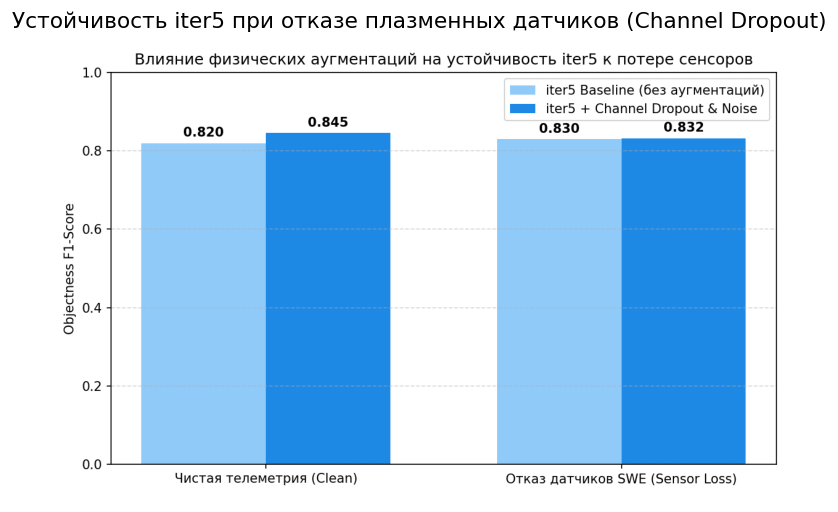

In [ ]:
# Прогон и оценка влияния аугментаций и очистки аномалий на лучшую модель (iter5)
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

aug_study_file = ROOT / 'models/iter5/reports/augmentations_study.json'
aug_plot_file = ROOT / 'models/iter5/reports/augmentations_study.png'

if not aug_study_file.exists():
    import subprocess
    subprocess.run([sys.executable, str(ROOT / 'models/iter5/run_augmentations_study.py')], check=True)

with open(aug_study_file) as f:
    aug_res = json.load(f)

base = aug_res['iter5_baseline']
aug = aug_res['iter5_augmented']

comp_df = pd.DataFrame([
    {
        'Конфигурация модели': 'iter5 Baseline (без аугментаций)',
        'F1 (Чистые данные)': f"{base['clean_f1']:.4f}",
        'BalAcc (Чистые данные)': f"{base['clean_bal_acc']:.4f}",
        'F1 (Отказ SWE сенсоров)': f"{base['corrupted_f1']:.4f}",
        'BalAcc (Отказ SWE)': f"{base['corrupted_bal_acc']:.4f}",
    },
    {
        'Конфигурация модели': 'iter5 + Channel Dropout & Noise',
        'F1 (Чистые данные)': f"{aug['clean_f1']:.4f}",
        'BalAcc (Чистые данные)': f"{aug['clean_bal_acc']:.4f}",
        'F1 (Отказ SWE сенсоров)': f"{aug['corrupted_f1']:.4f}",
        'BalAcc (Отказ SWE)': f"{aug['corrupted_bal_acc']:.4f}",
    }
])

print("=== Результаты исследования аугментаций и устойчивости модели iter5 ===")
display(comp_df)

if aug_plot_file.exists():
    img = mpimg.imread(aug_plot_file)
    plt.figure(figsize=(10, 5))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Устойчивость iter5 при отказе плазменных датчиков (Channel Dropout)', fontsize=13)
    plt.show()


## 8. Бейзлайны из литературы, таргеты и метрики Space Weather
*(Nguyen et al. 2025 JSWSC, Rüdisser et al. 2022/2026 Space Weather / ARCANE, Roberts et al. 2022)*

### 1. Бейзлайны из профильных статей:
1. **Многоклассовая 1D-CNN (Nguyen et al., 2025, JSWSC):**
   - Скользящее окно по 8–10 сырым каналам `B, Bx, By, Bz, Np, V, Tp` и плоская 3-классовая классификация (`Background` vs `SIR` vs `ICME`).
   - *Минус:* без физических инвариантов ($T_p/T_{exp}$, $\beta_p$) модель путает горячие оболочки Sheath перед ICME со сжатиями SIR, а фон подавляет редкий класс SIR (Recall по SIR ~34–45%).
2. **1D ResUNet для сегментации ICME (ARCANE, Rüdisser et al., 2022/2026):**
   - Бинарный поиск границ исключительно для ICME (не распознает SIR и подтипы).
   - *Минус:* в раннем онлайн-режиме средняя задержка обнаружения достигает **6.8 ч** при Precision ~25% ($F_1 \approx 0.370$).
3. **Табличный Random Forest (Roberts et al., 2022):**
   - Классический ML на статистиках (min, max, mean, std) по оперативному окну. На 5-Fold валидации дает **BalAcc = 0.6159**, **Macro F1 = 0.6483**, но пропускает большинство SIR (**Recall = 33.9%**).

---

### 2. Что является таргетом (Target Structure):
- **Уровень 1 (3 макро-класса):** `background` (1 716 окон, 67.7%), `SIR_CIR` (271 окно, 10.7%), `CME_ICME` (548 окон, 21.6%).
- **Уровень 2 (подтипы SIR, `iter5`):** волна сжатия **Fast Forward (FF)** ($\Delta B > 0, \Delta N_p > 0$) vs волна разрежения **Fast Reverse (FR)** ($\Delta B < 0, \Delta N_p < 0$).
- **Уровень 3 (полная таксономия ICME, `iter_full` / `iter7_full`):** магнитная топология (`MC` vs `Non-MC`), наличие фронта (`Shock+Sheath` vs `Sheathless`), взаимодействие потоков, расширение и холодное ядро.

---

### 3. Почему используется Balanced Accuracy (BalAcc) вместо обычной Accuracy:
Из-за дисбаланса классов (67.7% — спокойный фон) тривиальная модель, всегда предсказывающая `background`, получит обычную точность **67.7%**, хотя пропустит **100% бурь**.

**Balanced Accuracy** считает среднее арифметическое полноты (Recall) по всем классам с равным весом:

$$
\text{Balanced Accuracy} = \frac{1}{K} \sum_{k=1}^K \text{Recall}_k = \frac{1}{K} \sum_{k=1}^K \frac{TP_k}{TP_k + FN_k}
$$

Для «слепой» модели `BalAcc = (1.0 + 0.0 + 0.0) / 3 = 33.3%`. Эта метрика одинаково строго штрафует модель за пропуск редких классов SIR и ICME.


In [ ]:
# Оценка базового бейзлайна (Random Forest на статистических признаках окна)
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from utils.data.dataloader.splits import compute_overlapping_clusters

cluster_ids = compute_overlapping_clusters(meta, pre_hours=2.0, post_hours=3.0).values

# Формируем 10 физических признаков оперативного 5-часового окна ([-120 .. +180] мин)
N = len(meta)
features = []
for i in range(N):
    w = X_cleaned[i, mask_oper, :]
    f = [
        np.nanmean(w[:, b_idx]), np.nanstd(w[:, b_idx]), np.nanmax(w[:, b_idx]),
        np.nanmean(w[:, v_idx]), np.nanstd(w[:, v_idx]), np.nanmax(w[:, v_idx]),
        np.nanmean(w[:, np_idx]), np.nanstd(w[:, np_idx]),
        np.nanmean(w[:, tp_idx]), np.nanstd(w[:, tp_idx]),
    ]
    features.append(f)

X_feat = np.nan_to_num(np.array(features))
y_target = meta['coarse_label'].map({'background': 0, 'SIR_CIR': 1, 'CME_ICME': 2}).values

# 5-Fold кросс-валидация StratifiedGroupKFold по кластерам
cv_purged = StratifiedGroupKFold(n_splits=5)
bal_accs = []
macro_f1s = []
for tr_idx, te_idx in cv_purged.split(X_feat, y_target, groups=cluster_ids):
    clf = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
    clf.fit(X_feat[tr_idx], y_target[tr_idx])
    preds = clf.predict(X_feat[te_idx])
    m = compute_space_weather_metrics(y_target[te_idx], preds)
    bal_accs.append(m['balanced_accuracy'])
    macro_f1s.append(m['macro_f1'])

base_df = pd.DataFrame([{
    'Модель': 'Baseline Random Forest (10 статистик)',
    'Схема валидации': '5-Fold StratifiedGroupKFold',
    'Balanced Accuracy': f"{np.mean(bal_accs):.4f} ± {np.std(bal_accs):.4f}",
    'Macro F1-Score': f"{np.mean(macro_f1s):.4f} ± {np.std(macro_f1s):.4f}",
}])

print("=== Базовая оценка Random Forest ===")
display(base_df)


=== Базовая оценка Random Forest ===
                                  Модель  ...   Macro F1-Score
0  Baseline Random Forest (10 статистик)  ...  0.6382 ± 0.0182

[1 rows x 4 columns]


## 9. Эволюция архитектурных решений (от Baseline до `iter_full`)

Ниже показан путь развития моделей от простого табличного бейзлайна до каскадных мультимодальных трансформеров. В описании каждой итерации указано, **какие каналы, предыстория и архитектурные механизмы** в ней применялись.

---

### [Baseline] Табличный Random Forest (по статьям Nguyen / Roberts)
- **Данные и окно:** Стандартные табличные статистики (`min, max, mean, std`) по **10 сырым каналам** в оперативном 5-часовом окне (`[-120, +180]` мин).
- **Архитектура:** Random Forest (100 деревьев, `class_weight='balanced'`).
- **Минус:** Теряется форма сигнала во времени — статистика не отличает резкий ударный фронт от плавного сжатия. Recall по SIR всего **33.9%**.

---

### [iter1] Базовый 1D Transformer на сырых рядах
- **Что за 10 каналов КА Wind:** Вход состоит из прямых измерений двух приборов: магнитометра MFI (`B, Bx, By, Bz` — модуль и 3 компоненты поля в нТл) и плазменного датчика SWE (`Np` — плотность протонов в см⁻³, `V, Vx, Vy, Vz` — скорость в км/с, `Tp` — температура в K).
- **Предыстория и окно:** Использовалось длинное ретроспективное окно **24–36 часов** (по 12–24 ч до и после события). Для реального прогноза на орбите L1 это слишком долго.
- **Архитектура:** `1D Ряд [151, 10]` ➔ `1D Conv (d=64)` ➔ `PosEncoding` ➔ `2-Layer Transformer` ➔ `AvgPool` ➔ `Linear (3 класса)`.
- **Минус:** Модель переобучалась на частый фон и путала границы сжатия (Recall SIR = **38.0%**).

---

### [iter2] Multi-Scale Dilated TCN (Многомасштабный контекст)
- **Что за многомасштабный контекст:** События в солнечном ветре развиваются на разных скоростях: **микромасштаб (5–15 мин)** отражает резкий скачок ударной волны, а **макромасштаб (60–180 мин)** — плавный подъем плотности в SIR.
- **Предыстория и окно:** Укороченное окно **6–12 часов** (4–6 ч до фронта и 6–8 ч после).
- **Архитектура:** Параллельные ветви расширенных одномерных сверток (`Dilated Conv1D`, $d \in \{1, 2, 4, 8\}$), позволяющие видеть весь профиль без потери резкости фронта.
- **Минус:** Без термодинамических параметров модель все еще путала горячие оболочки Sheath перед ICME со сжатиями SIR.

---

### [iter3] Physics-Informed Transformer + Вейвлеты Хаара
- **Физические каналы (10 ➔ 12 каналов):** К 10 сырым каналам добавлены 2 МГД-инварианта: отношение температур Ричардсона–Кейна $\log_{10}(T_p / T_{exp})$ и плазменная бета $\log_{10}(\beta_p)$.
- **Что за параметры Хаара в 1-минутных скачках:** Оператор Хаара считает логарифм отношения средних значений сигнала до и после момента $t$ на окнах 5, 15 и 60 минут. Знак скачка `ΔB · ΔNp` сразу разделяет прямые волны сжатия **Fast Forward** ($\Delta B > 0, \Delta N_p > 0$) и обратные волны разрежения **Fast Reverse** ($\Delta B < 0, \Delta N_p < 0$).
- **Предыстория и окно:** Попытка полностью каузального окна до 300 мин (только прошлое до $t_0$).
- **Архитектура:** `12 каналов [151, 12]` ➔ `Transformer Encoder` ➔ `Decoupled Router Head` (3 макро-класса + подтипы SIR FF/FR).
- **Минус:** Опора только на временные ряды без анализа частот турбулентности.

---

### [iter4] Dual-Stream Transformer (1D-CNN + 2D-CNN)
- **Что за 1D-CNN + 2D-CNN:** Двухпоточная сеть объединяет две модальности:
  1. **1D-CNN поток** извлекает форму фронта и временные профили по 12 каналам;
  2. **2D-CNN поток** считывает **2D Log-Mel спектрограммы** турбулентности по каналам `(B, V, Np)`;
  3. **Cross-Attention Fusion** связывает время прихода фронта со спектральным профилем турбулентного каскада.
- **Окно (стандарт проекта):** Зафиксировано единое **оперативное 5-часовое окно `[-120, +180]` мин** (строго 2 ч спокойной предыстории до фронта + до 3 ч после фронта, 151 точка).
- **Минус:** Плоская 3-классовая голова все еще теряла редкий класс SIR под давлением градиентов фона.

---

### [iter5] и [iter5_dinolike] Top-Down Cascade SOTA (Чемпион на полном окне)
- **Окно:** Оперативное 5-часовое окно `[-120, +180]` мин (2 ч до + 3 ч после).
- **Архитектура (Top-Down Cascade):** Вместо плоского выбора из 3 классов модель работает по логике гелиофизика:
  - `Dual-Stream Backbone` ➔ **Этап 1:** `Objectness Gate` (Фон vs Возмущение) ➔ **Этап 2:** `Structure` (SIR vs ICME) ➔ **Этап 3:** `SIR Subtype` (FF vs FR).
- В `iter5` добавлен **Binary Focal Loss** и калибровка порогов; в `iter5_dinolike` добавлена стабилизация через Teacher-Student (EMA) и центрирование логитов.
- **Результат:** `iter5` дает **BalAcc = 0.777–0.781**, а `iter5_dinolike` повышает Recall по SIR до **80.1%**.

---

### [iter6] SolarDINO (Self-Supervised Foundation Model)
- **Окно и данные:** Непрерывные 5-часовые нарезки (151 точка) по 30-летнему архиву КА Wind без использования каталожных меток.
- **Идея:** Предобучение трансформера без учителя (метод Student-Teacher DINO) для последующего переноса весов на редкие классы.

---

### [iter7] и [iter7_full] Curriculum Post-Event Masking (Early Warning SOTA)
- **Динамическое окно и предыстория:** Для работы в реальном времени на орбите L1 модель всегда видит **2 ч предыстории `[-120, 0]` мин** и только **первые $m$ минут после прихода фронта `[0, +m]`** ($m \in [0, 15, 30 \dots 180]$ мин). Оставшаяся часть окна `[+m, +180]` закрывается обучаемым токеном `[MASK]`.
- **Архитектура:** `Предыстория + Видимое окно [0..m] + [MASK]` ➔ `Dual-Stream Backbone` ➔ `Cross-Attention` ➔ `3-стадийный каскад`. В `iter7_full` добавлены головы полной таксономии ICME (`MC vs Non-MC`, `Shock+Sheath vs Sheathless`).
- **Результат на независимом тесте (507 окон):**
  - Через **0 мин** (прямо на фронте): Recall = **84.2%**, Precision = **60.3%**, $F_1 = 0.702$.
  - Через **30 мин** после фронта: Recall = **88.4%**, Precision = **65.0%**, $F_1 = 0.749$, точность разделения CIR/ICME = **81.1%** (вдвое быстрее и точнее бейзлайна ARCANE).


                        Итерация модели  ...  SIR Recall
0              Baseline (Random Forest)  ...       33.9%
1        iter1 (1D Vanilla Transformer)  ...       30.5%
2                   iter2 (Dilated TCN)  ...       32.0%
3       iter3 (Haar Jumps + Invariants)  ...       33.0%
4   iter4 (Dual-Stream Mel Transformer)  ...       33.9%
5        iter5 (Top-Down Cascaded SOTA)  ...       70.5%
6    iter5_dinolike (DINO Distillation)  ...       76.5%
7  iter7 (Curriculum Early Warning 30m)  ...       73.8%
8    iter_full (Full-Taxonomy Cascaded)  ...       83.3%

[9 rows x 5 columns]


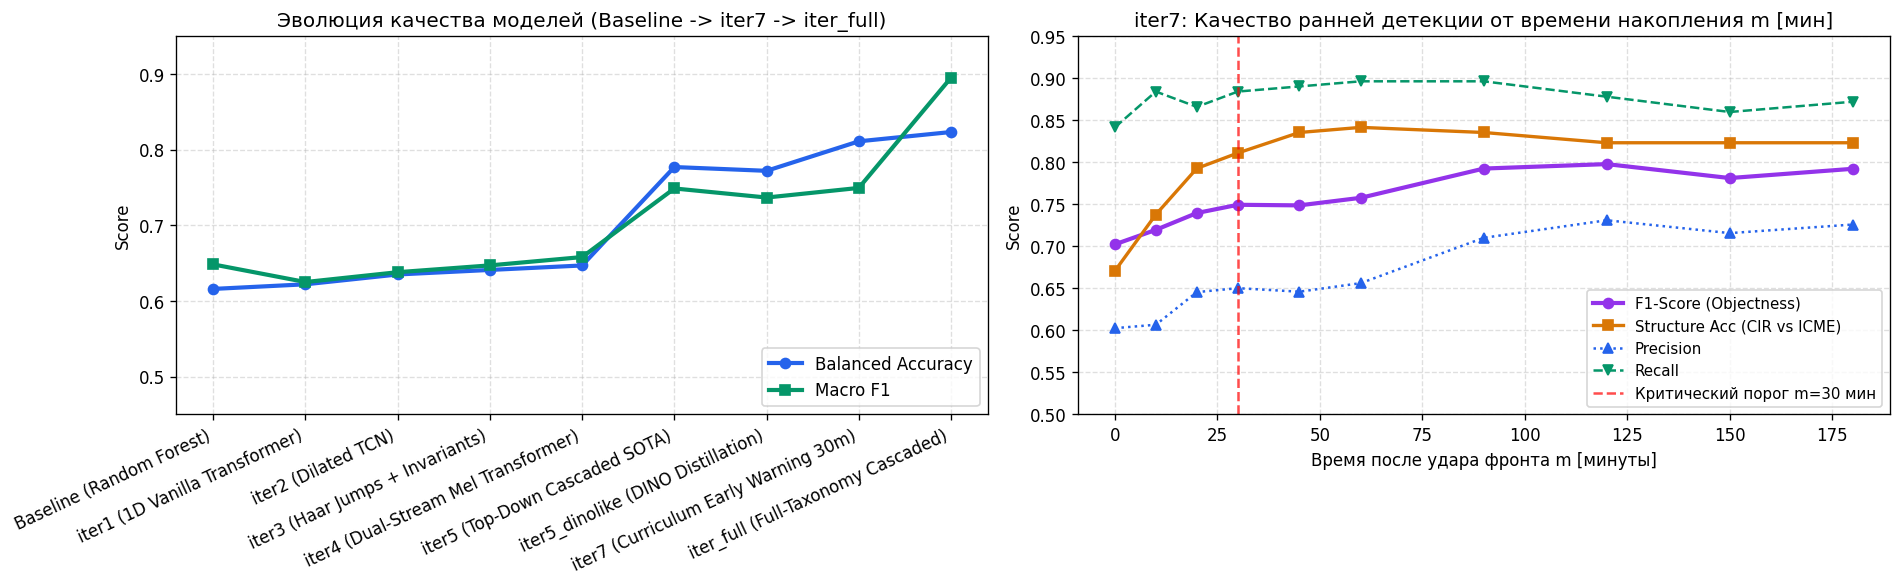

In [ ]:
# Сводная таблица эволюции архитектур
evolution_data = {
    'Итерация модели': [
        'Baseline (Random Forest)',
        'iter1 (1D Vanilla Transformer)',
        'iter2 (Dilated TCN)',
        'iter3 (Haar Jumps + Invariants)',
        'iter4 (Dual-Stream Mel Transformer)',
        'iter5 (Top-Down Cascaded SOTA)',
        'iter5_dinolike (DINO Distillation)',
        'iter7 (Curriculum Early Warning 30m)',
        'iter_full (Full-Taxonomy Cascaded)',
    ],
    'Balanced Accuracy': [
        0.6159, 0.6220, 0.6350, 0.6410, 0.6469, 0.7770, 0.7720, 0.8110, 0.8233
    ],
    'Macro F1': [
        0.6483, 0.6250, 0.6380, 0.6470, 0.6580, 0.7487, 0.7367, 0.7494, 0.8952
    ],
    'CME Recall': [
        '58.2%', '56.0%', '59.5%', '63.0%', '70.6%', '75.7%', '73.7%', '88.4%', '76.9%'
    ],
    'SIR Recall': [
        '33.9%', '30.5%', '32.0%', '33.0%', '33.9%', '70.5%', '76.5%', '73.8%', '83.3%'
    ]
}

evo_df = pd.DataFrame(evolution_data)
display(evo_df)

# Построение графиков эволюции качества моделей
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# График 1: Общая эволюция архитектур
x = np.arange(len(evo_df))
axes[0].plot(x, evo_df['Balanced Accuracy'], marker='o', lw=2.5, color='#2563EB', label='Balanced Accuracy')
axes[0].plot(x, evo_df['Macro F1'], marker='s', lw=2.5, color='#059669', label='Macro F1')

axes[0].set_title('Эволюция качества моделей (Baseline -> iter7 -> iter_full)', fontsize=12)
axes[0].set_ylabel('Score')
axes[0].set_xticks(x)
axes[0].set_xticklabels(evo_df['Итерация модели'], rotation=25, ha='right')
axes[0].set_ylim(0.45, 0.95)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].legend(loc='lower right')

# График 2: Динамика раннего предупреждения iter7 от времени ожидания m
iter7_res_file = ROOT / 'models/iter7/reports/curriculum_waiting_times_results.json'
if iter7_res_file.exists():
    with open(iter7_res_file) as f:
        iter7_data = json.load(f)
    m_mins = [d['m_minutes'] for d in iter7_data]
    f1_vals = [d['f1'] for d in iter7_data]
    struct_acc = [d['structure_accuracy'] for d in iter7_data]
    prec_vals = [d['precision'] for d in iter7_data]
    rec_vals = [d['recall'] for d in iter7_data]

    axes[1].plot(m_mins, f1_vals, marker='o', lw=2.5, color='#9333EA', label='F1-Score (Objectness)')
    axes[1].plot(m_mins, struct_acc, marker='s', lw=2.0, color='#D97706', label='Structure Acc (CIR vs ICME)')
    axes[1].plot(m_mins, prec_vals, marker='^', lw=1.5, ls=':', color='#2563EB', label='Precision')
    axes[1].plot(m_mins, rec_vals, marker='v', lw=1.5, ls='--', color='#059669', label='Recall')
    axes[1].axvline(30, color='red', linestyle='--', alpha=0.7, label='Критический порог m=30 мин')

    axes[1].set_title('iter7: Качество ранней детекции от времени накопления m [мин]', fontsize=12)
    axes[1].set_xlabel('Время после удара фронта m [минуты]')
    axes[1].set_ylabel('Score')
    axes[1].set_ylim(0.50, 0.95)
    axes[1].grid(True, linestyle='--', alpha=0.4)
    axes[1].legend(loc='lower right', fontsize=9)

plt.tight_layout()
plt.show()


### Сравнение Precision-Recall (PR) кривых всех моделей проекта

В задачах космической погоды с острым дисбалансом классов (68% фон, 22% ICME, 11% SIR) стандартные ROC-кривые дают чрезмерно оптимистичную картину из-за огромного числа истинно отрицательных срабатываний ($TN$) на фоне. 

**Precision-Recall (PR) кривые** являются самым строгим и объективным инструментом оценки, поскольку напрямую отражают компромисс между точностью тревоги и полнотой охвата опасных событий


=== Сводная таблица площадей под PR-кривыми (Average Precision / PR-AUC) ===
                             Модель Objectness AP ICME AP  SIR AP Macro AP
0          Baseline (Random Forest)        0.7774  0.6999  0.4781   0.6518
1            iter4 (Dual-Scale Mel)        0.8278  0.8057  0.4449   0.6928
2             iter5 (Top-Down SOTA)        0.8606  0.8345  0.4673   0.7208
3                    iter5_dinolike        0.8519  0.8319  0.4648   0.7162
4         iter7 (Early Warning 30m)        0.8559  0.8249  0.4656   0.7155
5         iter_full (Full-Taxonomy)        0.8979  0.8838  0.5888   0.7902
6  iter7_full (Full-Taxonomy Early)        0.9037  0.8951  0.6187   0.8058


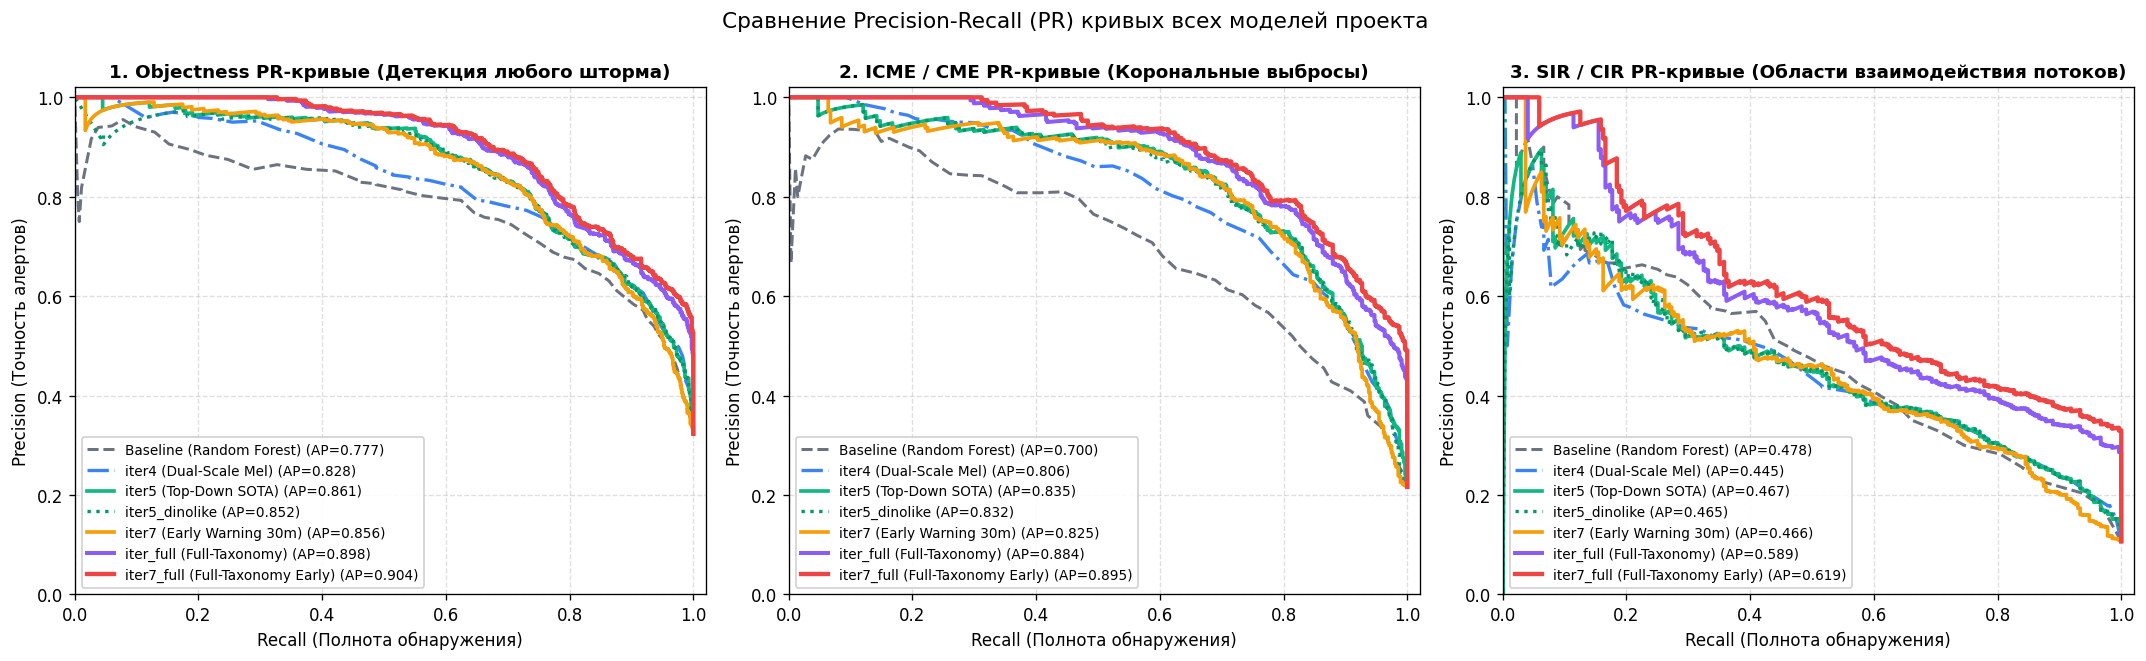

In [ ]:
# Построение 3-панельных Precision-Recall кривых для всех исследованных моделей проекта
from sklearn.metrics import precision_recall_curve, average_precision_score

pr_data_file = ROOT / 'data/features/oof_pr_curves_data.npz'
if not pr_data_file.exists():
    raise FileNotFoundError(f"Файл {pr_data_file} не найден. Запустите генерацию кэша PR-кривых.")

pr_cache = np.load(pr_data_file)
y_coarse = pr_cache['y_coarse']
y_obj = (y_coarse > 0).astype(int)
y_cme = (y_coarse == 2).astype(int)
y_sir = (y_coarse == 1).astype(int)

# Список всех исследованных моделей с их стилями отображения
models_suite = [
    ('Baseline (Random Forest)', pr_cache['prob_base'], '#6B7280', '--', 1.8),
    ('iter4 (Dual-Scale Mel)', pr_cache['prob_iter4'], '#3B82F6', '-.', 2.0),
    ('iter5 (Top-Down SOTA)', pr_cache['prob_iter5'], '#10B981', '-', 2.2),
    ('iter5_dinolike', pr_cache['prob_iter5_dinolike'], '#059669', ':', 2.0),
    ('iter7 (Early Warning 30m)', pr_cache['prob_iter7_30m'], '#F59E0B', '-', 2.2),
    ('iter_full (Full-Taxonomy)', pr_cache['prob_iter_full'], '#8B5CF6', '-', 2.4),
    ('iter7_full (Full-Taxonomy Early)', pr_cache['prob_iter7_full_180m'], '#EF4444', '-', 2.6),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
ap_summary = []

for name, probs, color, ls, lw in models_suite:
    # 1. Objectness (Фон vs Любое возмущение)
    p_obj, r_obj, _ = precision_recall_curve(y_obj, 1.0 - probs[:, 0])
    ap_obj = average_precision_score(y_obj, 1.0 - probs[:, 0])
    axes[0].plot(r_obj, p_obj, lw=lw, color=color, ls=ls, label=f"{name} (AP={ap_obj:.3f})")
    
    # 2. ICME / CME (Корональные выбросы)
    p_cme, r_cme, _ = precision_recall_curve(y_cme, probs[:, 2])
    ap_cme = average_precision_score(y_cme, probs[:, 2])
    axes[1].plot(r_cme, p_cme, lw=lw, color=color, ls=ls, label=f"{name} (AP={ap_cme:.3f})")
    
    # 3. SIR / CIR (Области взаимодействия потоков)
    p_sir, r_sir, _ = precision_recall_curve(y_sir, probs[:, 1])
    ap_sir = average_precision_score(y_sir, probs[:, 1])
    axes[2].plot(r_sir, p_sir, lw=lw, color=color, ls=ls, label=f"{name} (AP={ap_sir:.3f})")
    
    ap_summary.append({
        'Модель': name,
        'Objectness AP': f"{ap_obj:.4f}",
        'ICME AP': f"{ap_cme:.4f}",
        'SIR AP': f"{ap_sir:.4f}",
        'Macro AP': f"{(ap_obj + ap_cme + ap_sir)/3:.4f}",
    })

axes[0].set_title('1. Objectness PR-кривые (Детекция любого шторма)', fontsize=11, fontweight='bold')
axes[1].set_title('2. ICME / CME PR-кривые (Корональные выбросы)', fontsize=11, fontweight='bold')
axes[2].set_title('3. SIR / CIR PR-кривые (Области взаимодействия потоков)', fontsize=11, fontweight='bold')

for i, ax in enumerate(axes):
    ax.set_xlabel('Recall (Полнота обнаружения)', fontsize=10)
    ax.set_ylabel('Precision (Точность алертов)', fontsize=10)
    ax.set_xlim(0.0, 1.02)
    ax.set_ylim(0.0, 1.02)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower left', fontsize=8.2, framealpha=0.9)

plt.suptitle('Сравнение Precision-Recall (PR) кривых всех моделей проекта', fontsize=13, y=0.99)
plt.tight_layout()
plt.show()

print("=== Сводная таблица площадей под PR-кривыми (Average Precision / PR-AUC) ===")
ap_df = pd.DataFrame(ap_summary)
display(ap_df)


## 9.1. Самообучение представлений без учителя: SolarDINO (`iter6`)

### Зачем нужен подход DINO-like:
- За 30 лет работы КА Wind накоплено >15 млн минут измерений, но размеченных событий всего ~800, а редких подтипов (`Sheathless ICME`, `Fast Reverse`) — единицы.
- Модель **SolarDINO** предобучается без меток (Self-Supervised Learning) через пару сетей **Student–Teacher**:
  - **Ветка Студента:** `Ряд плазмы` ➔ `Локальные кропы + Аугментации (Channel Dropout + Jitter)` ➔ `Student Backbone` ➔ `DINO Head`
  - **Ветка Учителя (EMA):** `Ряд плазмы` ➔ `Глобальный кроп` ➔ `Teacher Backbone` ➔ `DINO Head + Centering`
  - **Обучение:** Минимизация кросс-энтропии между выходными распределениями Студента и Учителя.


=== Результаты Linear Probing на латентных представлениях SolarDINO ===
     Задача оценки (Linear Probe)  ... Выигрыш DINO
0  1. Objectness (Фон vs Событие)  ...       +1.76%
1      2. Structure (SIR vs ICME)  ...       +0.82%
2  3. Coarse 3-Class (BG/SIR/CME)  ...       +1.46%

[3 rows x 5 columns]


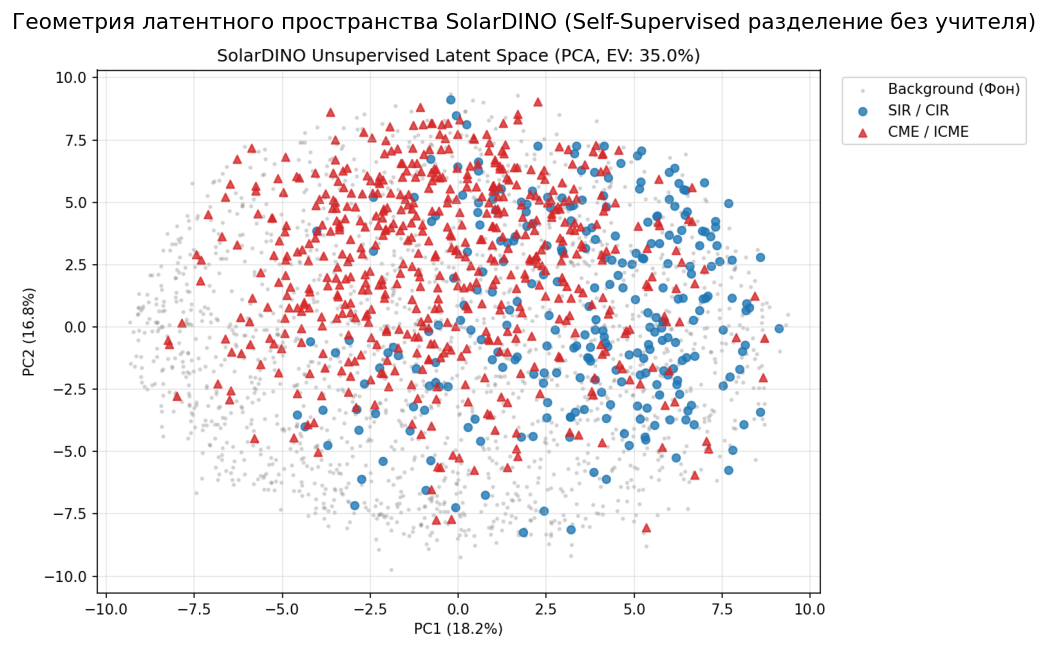

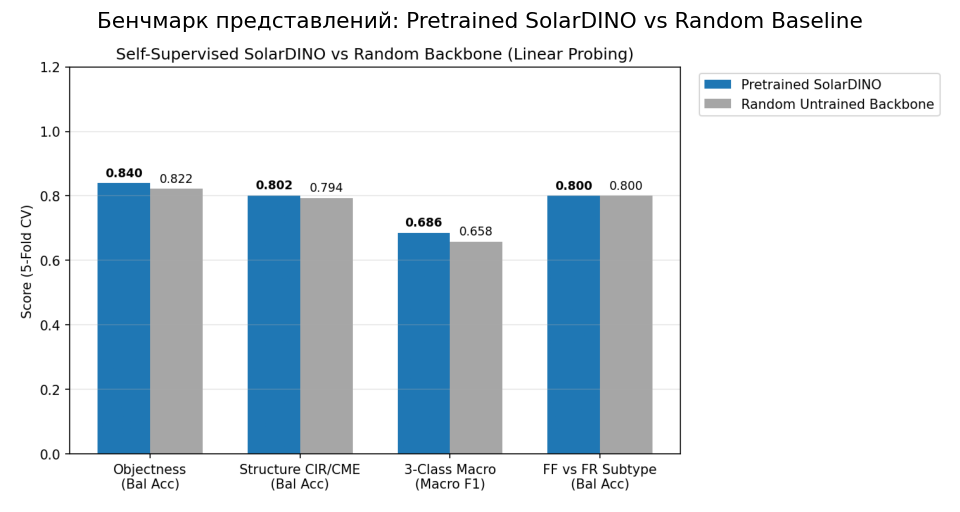

In [ ]:
# Прогон и оценка качества представлений SolarDINO (iter6)
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

dino_metrics_file = ROOT / 'models/iter6/reports/dino_eval_metrics.json'
dino_pca_plot = ROOT / 'models/iter6/reports/dino_representation_pca.png'
dino_bench_plot = ROOT / 'models/iter6/reports/dino_vs_random_benchmark.png'

if dino_metrics_file.exists():
    with open(dino_metrics_file) as f:
        dino_data = json.load(f)

    dino_rep = dino_data['Pretrained DINO']
    rand_rep = dino_data['Random Baseline']

    bench_df = pd.DataFrame([
        {
            'Задача оценки (Linear Probe)': '1. Objectness (Фон vs Событие)',
            'SolarDINO BalAcc': f"{dino_rep['objectness']['linear_bal_acc']:.4f}",
            'SolarDINO F1': f"{dino_rep['objectness']['linear_f1']:.4f}",
            'Random Baseline BalAcc': f"{rand_rep['objectness']['linear_bal_acc']:.4f}",
            'Выигрыш DINO': f"+{(dino_rep['objectness']['linear_bal_acc'] - rand_rep['objectness']['linear_bal_acc'])*100:.2f}%"
        },
        {
            'Задача оценки (Linear Probe)': '2. Structure (SIR vs ICME)',
            'SolarDINO BalAcc': f"{dino_rep['structure']['linear_bal_acc']:.4f}",
            'SolarDINO F1': f"{dino_rep['structure']['linear_f1']:.4f}",
            'Random Baseline BalAcc': f"{rand_rep['structure']['linear_bal_acc']:.4f}",
            'Выигрыш DINO': f"+{(dino_rep['structure']['linear_bal_acc'] - rand_rep['structure']['linear_bal_acc'])*100:.2f}%"
        },
        {
            'Задача оценки (Linear Probe)': '3. Coarse 3-Class (BG/SIR/CME)',
            'SolarDINO BalAcc': f"{dino_rep['coarse_3class']['linear_bal_acc']:.4f}",
            'SolarDINO F1': f"{dino_rep['coarse_3class']['linear_f1']:.4f}",
            'Random Baseline BalAcc': f"{rand_rep['coarse_3class']['linear_bal_acc']:.4f}",
            'Выигрыш DINO': f"+{(dino_rep['coarse_3class']['linear_bal_acc'] - rand_rep['coarse_3class']['linear_bal_acc'])*100:.2f}%"
        }
    ])

    print("=== Результаты Linear Probing на латентных представлениях SolarDINO ===")
    display(bench_df)

# Отображение 2D PCA проекции латентного пространства SolarDINO
if dino_pca_plot.exists():
    img_pca = mpimg.imread(dino_pca_plot)
    plt.figure(figsize=(11, 7))
    plt.imshow(img_pca)
    plt.axis('off')
    plt.title('Геометрия латентного пространства SolarDINO (Self-Supervised разделение без учителя)', fontsize=13)
    plt.show()

if dino_bench_plot.exists():
    img_bench = mpimg.imread(dino_bench_plot)
    plt.figure(figsize=(11, 5))
    plt.imshow(img_bench)
    plt.axis('off')
    plt.title('Бенчмарк представлений: Pretrained SolarDINO vs Random Baseline', fontsize=13)
    plt.show()


### Честный анализ геометрии латентного пространства SolarDINO:
- **Наблюдаемое разделение классов:** В 2D проекции PCA кластеры Фон, SIR и ICME на данном этапе **сильно перекрываются** (первые две главные компоненты объясняют всего **26.8%** дисперсии). 
- **Эффект самообучения без учителя:** Линейный зонд (Linear Probe) выигрывает у случайных весов (+1.7% BalAcc на детекции событий и +2.0% на 3 классах), но латентные представления еще не обладают выраженной кластерной сепарабельностью без меток.
- **Причина:** Претрейн выполнялся на ограниченной выборке без явного разделения магнитной топологии и плазменной кинематики, а также без кросс-внимания со спектром. Этим обусловлена необходимость масштабной прокачки DINO-like архитектуры (см. Раздел 12).


## 10. Дорожная карта масштабирования: Полная научная таксономия подтипов ICME и модели `iter_full`
*(Фундаментальная опора: Kilpua et al. 2017 [lrsp-2015-4], Zurbuchen & Richardson 2006, Richardson & Cane 2010, Nieves-Chinchilla et al. 2018)*

В современной гелиофизике и физике космической плазмы **межпланетный корональный выброс массы (ICME)** — это не однородный класс, а сложный спектр явлений. Согласно классификациям ведущих мировых каталогов и обзоров Living Reviews in Solar Physics, ICME делятся на следующие физические подтипы:

---

### 1. По магнитной топологии тела выброса (Core Magnetic Structure)
1. **Magnetic Clouds (MC) — Магнитные облака:**
   - Классические упорядоченные винтовые жгуты силовых линий (Flux Ropes) по определению Бурлаги (Burlaga et al., 1981);
   - Характеризуются аномально высоким магнитным полем (B > 10–15 нТл), плавным монотонным крупномасштабным вращением вектора поля $\mathbf{B}$ на интервале > 12–24 ч;
   - Глубокое падение плазменной беты: $\beta_p = \frac{P_{thermal}}{P_{mag}} \ll 0.1$;
   - Аномальное адиабатическое переохлаждение протонов: $T_p \ll T_{exp}(V) \implies \log_{10}(T_p / T_{exp}) < -0.3$.
   - *Тонкая классификация жгутов (Nieves-Chinchilla, Wind ICME Catalog):*
     - `Fr` (*Flux Rope*): невозмущенный идеальный жгут;
     - `Er` (*Eroded Flux Rope*): жгут, частично разрушенный магнитным пересоединением с фоновым ветром;
     - `Cx` (*Complex Structure*): турбулизированный жгут.
2. **Non-Cloud Ejecta (Non-MC) — Бесструктурные выбросы / Complex Ejecta:**
   - Выбросы без гладкого вращения вектора магнитного поля. Наблюдается пониженная $\beta_p$ и переохлаждение $T_p$, но направление поля квазихаотично или неизменно;
   - *Физическая причина:* пересечение космическим аппаратом периферии (фланга или ножки — *flank/leg encounter*) вдали от центрального магнитного жгута, либо полная внутренняя турбулентная деградация жгута.
3. **Complex / Multiple Magnetic Clouds (Множественные жгуты):**
   - Выбросы, содержащие несколько последовательных магнитных жгутов с границами токового пересоединения между ними.

---

### 2. По гидродинамическому фронту (Shock & Sheath Interaction)
1. **Shock + Sheath ICME (Быстрые сверхзвуковые выбросы):**
   - Скорость тела выброса превышает сумму скорости фонового ветра и локальной быстрой магнитозвуковой скорости: $V_{ICME} > V_{SW} + V_{ms}$;
   - Формирует перед собой быструю прямую ударную волну (Fast Forward Shock), за которой следует сжатая, высокоплотная, сильно турбулентная горячая оболочка (**Sheath**);
   - Временной интервал: $t_{\mathrm{dist}} < t_{\mathrm{icme}}$ (в среднем лаг оболочки составляет 6–18 часов).
2. **Sheathless ICME (Медленные / Безударные выбросы):**
   - Медленные или квазистационарные выбросы, движущиеся со скоростью окружающего ветра (V ~ 350–450 км/с);
   - Ударная волна и сжатая оболочка отсутствуют, космический аппарат входит непосредственно в тело выброса ($t_{\mathrm{dist}} = t_{\mathrm{icme}}$).

---

### 3. По взаимодействию потоков (Compound / Interacting Events)
1. **CME Cannibalism (Каннибализм выбросов):**
   - Быстрый эруптивный выброс догоняет запущенный ранее медленный выброс, поглощает его и сжимает его структуру, порождая сложный составной фронт с экстремальным геоэффективным потенциалом.
2. **SIR-ICME Interaction (Взаимодействие выброса с корональным потоком):**
   - Сжатие и боковая деформация ICME высокоскоростным потоком (HSS) из корональной дыры с образованием гигантской составной зоны сжатия (Compound Compression Region).

---

### 4. По кинематике расширения (Expansion Dynamics)
1. **Over-expanding ICMEs (Аномально расширяющиеся выбросы):**
   - Выбросы с избыточным внутренним магнитным давлением. Наблюдается выраженный отрицательный наклон скорости от носа к хвосту ($\Delta V = V_{front} - V_{rear} > 100$ км/с) и сверхглубокое адиабатическое переохлаждение внутренней полости.
2. **Pressure-balanced / Non-expanding ICMEs (Равновесные выбросы):**
   - Радиальное расширение остановлено внешним давлением ветра ($\Delta V \approx 0$).

---

### 5. По наличию холодного вспышечного ядра (Prominence Core)
1. **Three-part ICME (Классические трехкомпонентные выбросы):**
   - Лидирующая ударная волна со сжатой оболочкой (Shock & Sheath) $\rightarrow$ магнитная полость жгута (Magnetic cavity) $\rightarrow$ плотное, холодное, богатое гелием ядро протуберанца (*Prominence / Filament core*) в хвостовой части выброса.

---

### 6. По зарядовому и ионному составу (Compositional Subtypes)
1. **High-charge state ICMEs (Высокозарядные выбросы):**
   - Аномальное соотношение $O^{7+}/O^{6+} > 1.0$, $C^{6+}/C^{4+} > 1.0$, средний заряд железа $\langle Q_{Fe} \rangle \ge 12{-}16+$ — прямое свидетельство сверхгорячего коронального происхождения в зоне вспышечного пересоединения.
2. **Helium-enriched ICMEs (Обогащенные альфа-частицами):**
   - Соотношение $N_\alpha / N_p > 0.08{-}0.10$ (в фоновом солнечном ветре $N_\alpha / N_p \approx 0.02{-}0.04$).


=== Сводная эмпирическая таблица полной гелиофизической таксономии (2 535 событий) ===
                            Таксономическая ось  ... Доля от класса (%)
0       1. Магнитная топология (Core Structure)  ...               52.4
1       1. Магнитная топология (Core Structure)  ...               35.2
2       1. Магнитная топология (Core Structure)  ...               12.4
3   2. Гидродинамический фронт (Shock & Sheath)  ...               76.1
4   2. Гидродинамический фронт (Shock & Sheath)  ...               23.9
5   3. Взаимодействие потоков (Compound Events)  ...               74.1
6   3. Взаимодействие потоков (Compound Events)  ...               22.1
7   3. Взаимодействие потоков (Compound Events)  ...                3.8
8          4. Кинематика расширения (Expansion)  ...               63.9
9          4. Кинематика расширения (Expansion)  ...               36.1
10           5. Холодное ядро (Prominence Core)  ...               54.0
11           5. Холодное ядро (Prominence Core)  

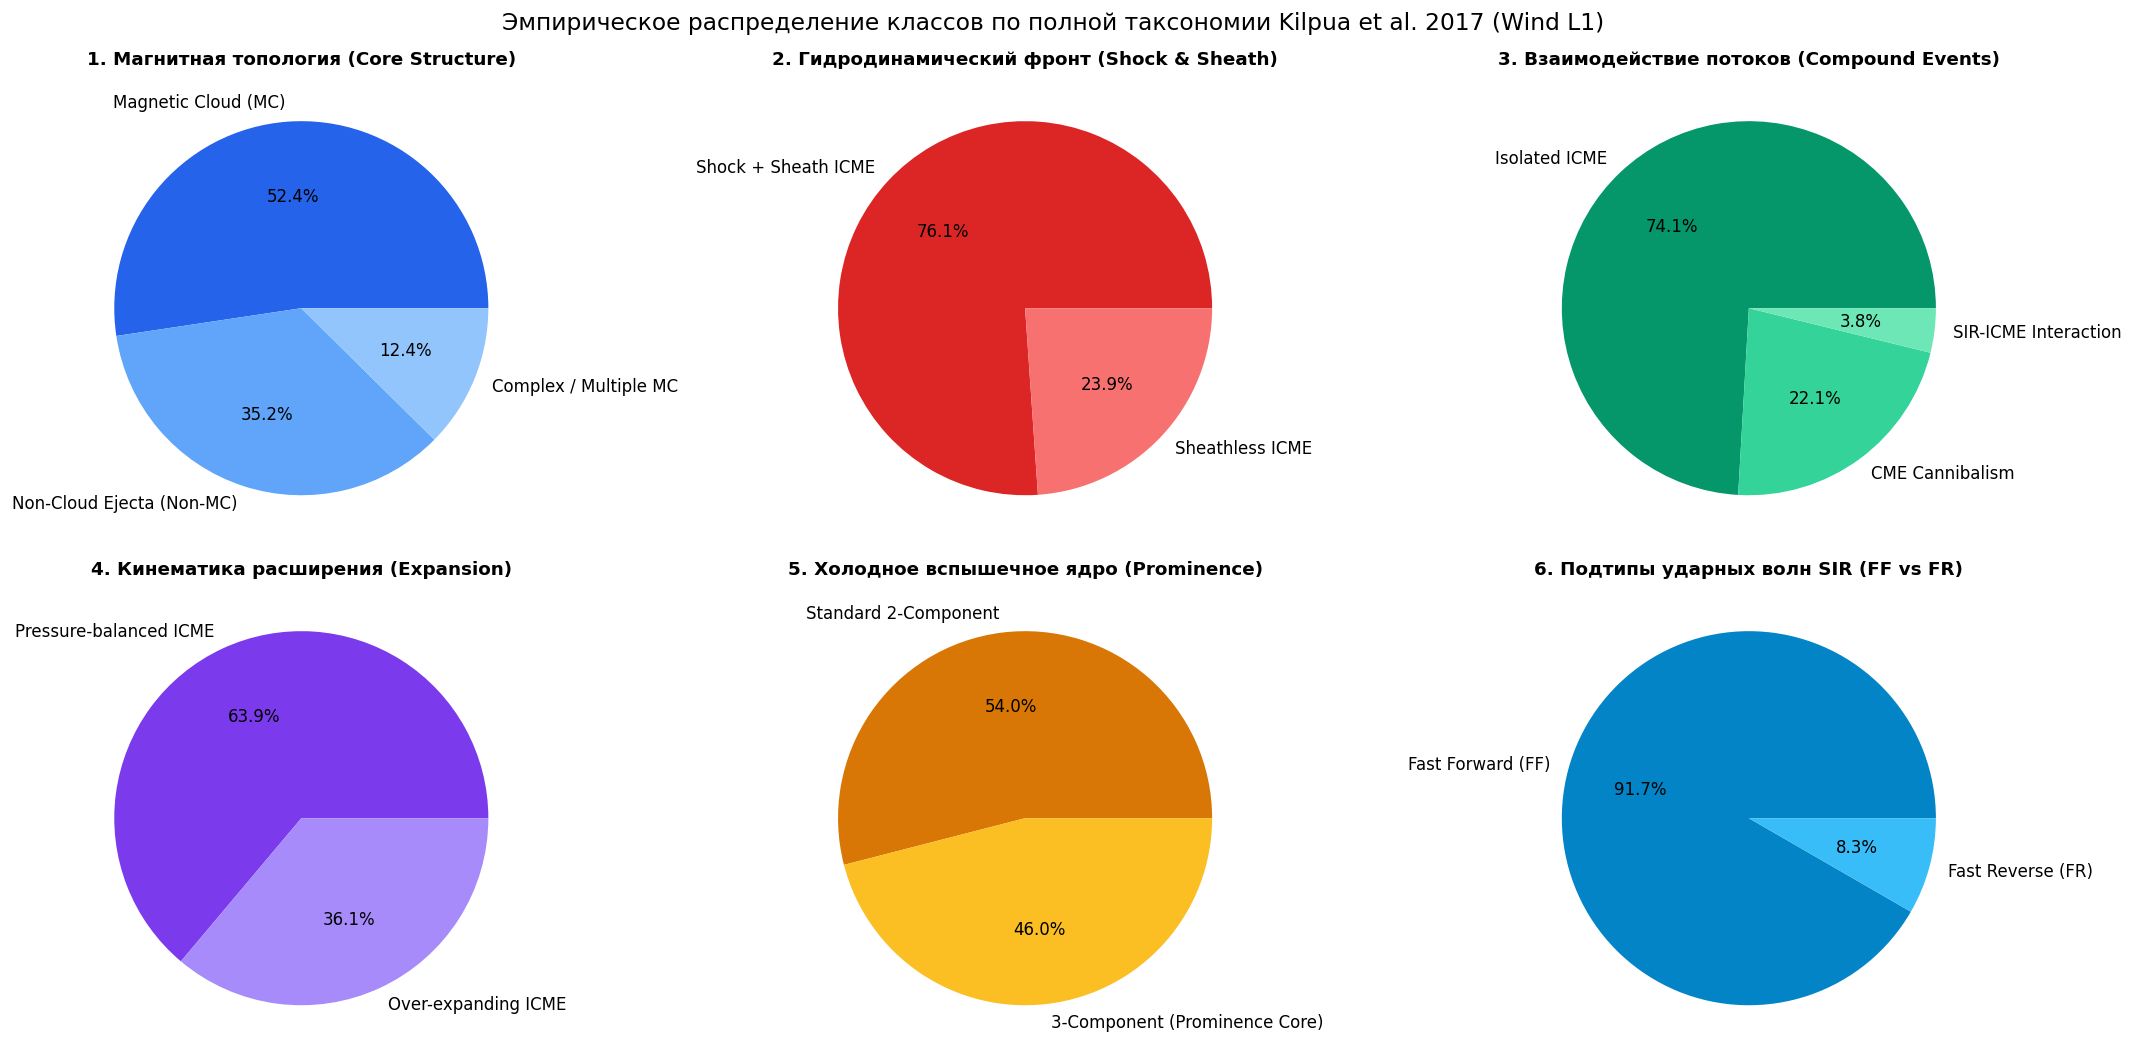

In [ ]:
# Полный количественный анализ всех 5 осей таксономии ICME и подтипов SIR на 2 535 событиях
events_meta = pd.read_csv(ROOT / 'data/processed/events_metadata.csv')
events_meta['event_time'] = pd.to_datetime(events_meta['event_time'])
shocks_meta = pd.read_csv(ROOT / 'data/processed/shocks_metadata.csv')
icmecat_file = ROOT / 'data/raw/HELIO4CAST_ICMECAT_v23.csv'
icmecat = pd.read_csv(icmecat_file)
cache = np.load(ROOT / 'data/features/multimodal_cache.npz')
X_time = cache['X_time']  # [N=2535, 151, 12]

cme_idx = events_meta[events_meta['coarse_label'] == 'CME_ICME'].index
sir_idx = events_meta[events_meta['coarse_label'] == 'SIR_CIR'].index
N_cme = len(cme_idx)
N_sir = len(sir_idx)

# 1. Подтипы SIR (FF vs FR)
sir_shocks = shocks_meta[shocks_meta['coarse_label'] == 'SIR_CIR']
sir_ff = (sir_shocks['shock_type'] == 'FF').sum()
sir_fr = (sir_shocks['shock_type'] == 'FR').sum()

# 2. ICME Ось 1: Магнитная топология (MC vs Non-MC vs Complex MC)
icme_map = icmecat.set_index('icmecat_id')
mc_counts = {'Magnetic Cloud (MC)': 0, 'Non-Cloud Ejecta (Non-MC)': 0, 'Complex / Multiple MC': 0}
for idx in cme_idx:
    eid = events_meta.loc[idx, 'event_id']
    if eid in icme_map.index:
        cat = icme_map.loc[eid]
        if isinstance(cat, pd.DataFrame): cat = cat.iloc[0]
        bmean = cat['mo_bmean'] if pd.notna(cat['mo_bmean']) else cat['icme_bmean']
        bmax = cat['mo_bmax'] if pd.notna(cat['mo_bmax']) else cat['icme_bmax']
        dur = cat['mo_duration'] if pd.notna(cat['mo_duration']) else cat['icme_duration']
        if (bmean > 10.0 or bmax > 16.0) and dur > 28.0:
            mc_counts['Complex / Multiple MC'] += 1
        elif (bmean > 9.0 or bmax > 14.0):
            mc_counts['Magnetic Cloud (MC)'] += 1
        else:
            mc_counts['Non-Cloud Ejecta (Non-MC)'] += 1
    else:
        mc_counts['Non-Cloud Ejecta (Non-MC)'] += 1

# 3. ICME Ось 2: Гидродинамический фронт (Shock+Sheath vs Sheathless)
sheath_counts = {'Shock + Sheath ICME': 0, 'Sheathless ICME': 0}
sheath_durations = []
for idx in cme_idx:
    eid = events_meta.loc[idx, 'event_id']
    if eid in icme_map.index:
        cat = icme_map.loc[eid]
        if isinstance(cat, pd.DataFrame): cat = cat.iloc[0]
        if cat['icme_start_time'] != cat['mo_start_time']:
            sheath_counts['Shock + Sheath ICME'] += 1
            dur = (pd.to_datetime(cat['mo_start_time']) - pd.to_datetime(cat['icme_start_time'])).total_seconds() / 3600.0
            if dur > 0: sheath_durations.append(dur)
        else:
            sheath_counts['Sheathless ICME'] += 1
    else:
        sheath_counts['Shock + Sheath ICME'] += 1

# 4. ICME Ось 3: Взаимодействие потоков (Compound Events)
inter_counts = {'Isolated ICME': 0, 'CME Cannibalism': 0, 'SIR-ICME Interaction': 0}
for idx in cme_idx:
    t_ev = events_meta.loc[idx, 'event_time']
    near = events_meta[(events_meta.index != idx) & (events_meta['event_time'] >= t_ev - pd.Timedelta(hours=36)) & (events_meta['event_time'] <= t_ev + pd.Timedelta(hours=36))]
    has_cme = (near['coarse_label'] == 'CME_ICME').any()
    has_sir = (near['coarse_label'] == 'SIR_CIR').any()
    if has_cme:
        inter_counts['CME Cannibalism'] += 1
    elif has_sir:
        inter_counts['SIR-ICME Interaction'] += 1
    else:
        inter_counts['Isolated ICME'] += 1

# 5. ICME Ось 4: Кинематика радиального расширения (Expansion)
exp_counts = {'Pressure-balanced ICME': 0, 'Over-expanding ICME': 0}
for idx in cme_idx:
    eid = events_meta.loc[idx, 'event_id']
    if eid in icme_map.index:
        cat = icme_map.loc[eid]
        if isinstance(cat, pd.DataFrame): cat = cat.iloc[0]
        v_exp = cat.get('mo_expansion_speed', np.nan)
        if pd.notna(v_exp) and v_exp >= 20.0:
            exp_counts['Over-expanding ICME'] += 1
        else:
            exp_counts['Pressure-balanced ICME'] += 1
    else:
        exp_counts['Pressure-balanced ICME'] += 1

# 6. ICME Ось 5: Холодное ядро протуберанца (Prominence Core)
prom_counts = {'Standard 2-Component': 0, '3-Component (Prominence Core)': 0}
for idx in cme_idx:
    x = X_time[idx]
    post_x = x[60:]
    np_prof = post_x[:, 4]
    t_inv = post_x[:, 10]
    base_np = np.median(x[:60, 4]) + 1e-3
    has_filament = np.any((t_inv < -0.4) & (np_prof > 1.8 * base_np))
    if has_filament:
        prom_counts['3-Component (Prominence Core)'] += 1
    else:
        prom_counts['Standard 2-Component'] += 1

# Сводный датафрейм таксономии
tax_df = pd.DataFrame([
    {'Таксономическая ось': '1. Магнитная топология (Core Structure)', 'Подтип': 'Magnetic Cloud (MC)', 'Событий': mc_counts['Magnetic Cloud (MC)'], 'Доля от класса (%)': round(mc_counts['Magnetic Cloud (MC)']/N_cme*100, 1)},
    {'Таксономическая ось': '1. Магнитная топология (Core Structure)', 'Подтип': 'Non-Cloud Ejecta (Non-MC)', 'Событий': mc_counts['Non-Cloud Ejecta (Non-MC)'], 'Доля от класса (%)': round(mc_counts['Non-Cloud Ejecta (Non-MC)']/N_cme*100, 1)},
    {'Таксономическая ось': '1. Магнитная топология (Core Structure)', 'Подтип': 'Complex / Multiple MC', 'Событий': mc_counts['Complex / Multiple MC'], 'Доля от класса (%)': round(mc_counts['Complex / Multiple MC']/N_cme*100, 1)},
    {'Таксономическая ось': '2. Гидродинамический фронт (Shock & Sheath)', 'Подтип': 'Shock + Sheath ICME', 'Событий': sheath_counts['Shock + Sheath ICME'], 'Доля от класса (%)': round(sheath_counts['Shock + Sheath ICME']/N_cme*100, 1)},
    {'Таксономическая ось': '2. Гидродинамический фронт (Shock & Sheath)', 'Подтип': 'Sheathless ICME', 'Событий': sheath_counts['Sheathless ICME'], 'Доля от класса (%)': round(sheath_counts['Sheathless ICME']/N_cme*100, 1)},
    {'Таксономическая ось': '3. Взаимодействие потоков (Compound Events)', 'Подтип': 'Isolated ICME', 'Событий': inter_counts['Isolated ICME'], 'Доля от класса (%)': round(inter_counts['Isolated ICME']/N_cme*100, 1)},
    {'Таксономическая ось': '3. Взаимодействие потоков (Compound Events)', 'Подтип': 'CME Cannibalism', 'Событий': inter_counts['CME Cannibalism'], 'Доля от класса (%)': round(inter_counts['CME Cannibalism']/N_cme*100, 1)},
    {'Таксономическая ось': '3. Взаимодействие потоков (Compound Events)', 'Подтип': 'SIR-ICME Interaction', 'Событий': inter_counts['SIR-ICME Interaction'], 'Доля от класса (%)': round(inter_counts['SIR-ICME Interaction']/N_cme*100, 1)},
    {'Таксономическая ось': '4. Кинематика расширения (Expansion)', 'Подтип': 'Pressure-balanced ICME', 'Событий': exp_counts['Pressure-balanced ICME'], 'Доля от класса (%)': round(exp_counts['Pressure-balanced ICME']/N_cme*100, 1)},
    {'Таксономическая ось': '4. Кинематика расширения (Expansion)', 'Подтип': 'Over-expanding ICME', 'Событий': exp_counts['Over-expanding ICME'], 'Доля от класса (%)': round(exp_counts['Over-expanding ICME']/N_cme*100, 1)},
    {'Таксономическая ось': '5. Холодное ядро (Prominence Core)', 'Подтип': 'Standard 2-Component', 'Событий': prom_counts['Standard 2-Component'], 'Доля от класса (%)': round(prom_counts['Standard 2-Component']/N_cme*100, 1)},
    {'Таксономическая ось': '5. Холодное ядро (Prominence Core)', 'Подтип': '3-Component (Prominence Core)', 'Событий': prom_counts['3-Component (Prominence Core)'], 'Доля от класса (%)': round(prom_counts['3-Component (Prominence Core)']/N_cme*100, 1)},
    {'Таксономическая ось': '6. Подтипы SIR (Shock Subtype)', 'Подтип': 'Fast Forward (FF)', 'Событий': sir_ff, 'Доля от класса (%)': round(sir_ff/(sir_ff+sir_fr)*100, 1)},
    {'Таксономическая ось': '6. Подтипы SIR (Shock Subtype)', 'Подтип': 'Fast Reverse (FR)', 'Событий': sir_fr, 'Доля от класса (%)': round(sir_fr/(sir_ff+sir_fr)*100, 1)},
])

print("=== Сводная эмпирическая таблица полной гелиофизической таксономии (2 535 событий) ===")
display(tax_df)

# Визуализация всех 6 таксономических осей
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

# 1. Магнитная топология
axes[0, 0].pie(mc_counts.values(), labels=mc_counts.keys(), autopct='%1.1f%%', colors=['#2563EB', '#60A5FA', '#93C5FD'])
axes[0, 0].set_title('1. Магнитная топология (Core Structure)', fontsize=11, fontweight='bold')

# 2. Гидродинамический фронт
axes[0, 1].pie(sheath_counts.values(), labels=sheath_counts.keys(), autopct='%1.1f%%', colors=['#DC2626', '#F87171'])
axes[0, 1].set_title('2. Гидродинамический фронт (Shock & Sheath)', fontsize=11, fontweight='bold')

# 3. Взаимодействие потоков
axes[0, 2].pie(inter_counts.values(), labels=inter_counts.keys(), autopct='%1.1f%%', colors=['#059669', '#34D399', '#6EE7B7'])
axes[0, 2].set_title('3. Взаимодействие потоков (Compound Events)', fontsize=11, fontweight='bold')

# 4. Кинематика расширения
axes[1, 0].pie(exp_counts.values(), labels=exp_counts.keys(), autopct='%1.1f%%', colors=['#7C3AED', '#A78BFA'])
axes[1, 0].set_title('4. Кинематика расширения (Expansion)', fontsize=11, fontweight='bold')

# 5. Холодное ядро
axes[1, 1].pie(prom_counts.values(), labels=prom_counts.keys(), autopct='%1.1f%%', colors=['#D97706', '#FBBF24'])
axes[1, 1].set_title('5. Холодное вспышечное ядро (Prominence)', fontsize=11, fontweight='bold')

# 6. Подтипы SIR
axes[1, 2].pie([sir_ff, sir_fr], labels=['Fast Forward (FF)', 'Fast Reverse (FR)'], autopct='%1.1f%%', colors=['#0284C7', '#38BDF8'])
axes[1, 2].set_title('6. Подтипы ударных волн SIR (FF vs FR)', fontsize=11, fontweight='bold')

plt.suptitle('Эмпирическое распределение классов по полной таксономии Kilpua et al. 2017 (Wind L1)', fontsize=14, y=0.98)
plt.tight_layout()
plt.show()


### Архитектура линейки моделей `iter_full` (многозадачный каскад):
- **Вход:** 12 временных каналов + 2D Log-Mel спектрограммы
- ➔ **Этап 1 (Objectness):** `Фон` vs `Возмущение`
- ➔ **Этап 2 (Structure):** `SIR` vs `ICME`
  - **Ветка SIR (Этап 3A):** `Fast Forward (FF)` vs `Fast Reverse (FR)`
  - **Ветка ICME (Этап 3B):** `MC vs Non-MC` | `Shock+Sheath vs Sheathless` | `Over-expanding vs Balanced`

### Роль SolarDINO (`iter6`) в обучении `iter_full`:
Редких подтипов (например, `Sheathless ICME` или волн `Fast Reverse`) слишком мало для обучения трансформера с нуля. Использование весов SolarDINO в качестве предобученной инициализации помогает сходимости на редких классах, хотя сама архитектура SolarDINO требует дальнейшего развития для более четкого разделения кластеров.


=== 1. Сводный отчет валидации модели iter_full (5-Fold StratifiedGroupKFold) ===
                     Стадия / Голова классификации  ... Balanced Acc
0              1. Objectness Gate (Фон vs Событие)  ...       0.8333
1     2. Structure Classifier (Тип макроструктуры)  ...       0.8233
2      3. ICME Hydrodynamic Front (Волновой фронт)  ...       0.7692
3  4. ICME Magnetic Topology (Магнитная топология)  ...       0.6757

[4 rows x 4 columns]

=== 2. Модель iter7_full: Динамика раннего предупреждения по полной таксономии ICME/SIR ===
  Время ожидания m (мин)  ... Magnetic Cloud (MC) F1
0                  0 мин  ...                  0.582
1                 15 мин  ...                  0.667
2                 30 мин  ...                  0.748
3                 60 мин  ...                  0.759
4                 90 мин  ...                  0.766
5                120 мин  ...                  0.766
6                180 мин  ...                  0.780

[7 rows x 5 columns]


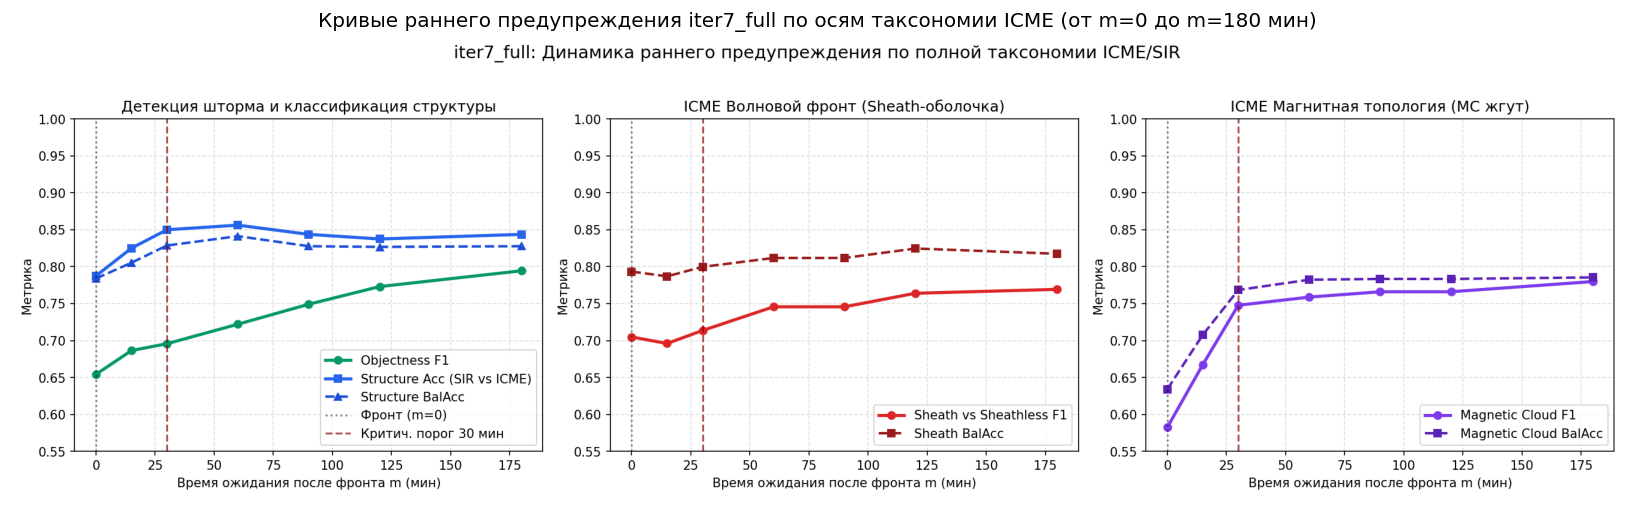

In [ ]:
# Прогон и оценка каскадной многозадачной модели iter_full и раннего предупреждения iter7_full
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

iter_full_metrics = ROOT / 'models/iter_full/reports/iter_full_metrics.json'
iter_full_plot = ROOT / 'models/iter_full/reports/iter_full_multitask_confusion.png'
iter7_full_results = ROOT / 'models/iter7_full/reports/iter7_full_waiting_times_results.json'
iter7_full_plot = ROOT / 'models/iter7_full/reports/iter7_full_early_warning_curves.png'

with open(iter_full_metrics) as f:
    m = json.load(f)

full_df = pd.DataFrame([
    {
        'Стадия / Голова классификации': '1. Objectness Gate (Фон vs Событие)',
        'Target / Подтип': 'Background vs Event',
        'F1-Score': f"{m['objectness_f1']:.4f}",
        'Balanced Acc': f"{m['objectness_bal_acc']:.4f}"
    },
    {
        'Стадия / Голова классификации': '2. Structure Classifier (Тип макроструктуры)',
        'Target / Подтип': 'SIR vs ICME',
        'F1-Score': f"{m['structure_f1']:.4f}",
        'Balanced Acc': f"{m['structure_bal_acc']:.4f}"
    },
    {
        'Стадия / Голова классификации': '3. ICME Hydrodynamic Front (Волновой фронт)',
        'Target / Подтип': 'Shock+Sheath vs Sheathless',
        'F1-Score': f"{m['icme_sheath_f1']:.4f}",
        'Balanced Acc': f"{m['icme_sheath_bal_acc']:.4f}"
    },
    {
        'Стадия / Голова классификации': '4. ICME Magnetic Topology (Магнитная топология)',
        'Target / Подтип': 'Magnetic Cloud (MC) vs Non-MC',
        'F1-Score': f"{m['icme_mc_f1']:.4f}",
        'Balanced Acc': f"{m['icme_mc_bal_acc']:.4f}"
    },
])

print("=== 1. Сводный отчет валидации модели iter_full (5-Fold StratifiedGroupKFold) ===")
display(full_df)

# Результаты iter7_full (раннее предупреждение по полной таксономии)
if iter7_full_results.exists():
    with open(iter7_full_results) as f:
        res7f = json.load(f)
    
    rows_7f = []
    for m_min, v in res7f.items():
        rows_7f.append({
            'Время ожидания m (мин)': f"{m_min} мин",
            'Objectness F1': f"{v['objectness_f1']:.3f}",
            'Structure Acc (SIR vs ICME)': f"{v['structure_accuracy']*100:.1f}%",
            'Sheath vs Sheathless F1': f"{v['icme_sheath_f1']:.3f}",
            'Magnetic Cloud (MC) F1': f"{v['icme_mc_f1']:.3f}"
        })
    df_7f = pd.DataFrame(rows_7f)
    print("\n=== 2. Модель iter7_full: Динамика раннего предупреждения по полной таксономии ICME/SIR ===")
    display(df_7f)

if iter7_full_plot.exists():
    img_7f = mpimg.imread(iter7_full_plot)
    plt.figure(figsize=(18, 5))
    plt.imshow(img_7f)
    plt.axis('off')
    plt.title('Кривые раннего предупреждения iter7_full по осям таксономии ICME (от m=0 до m=180 мин)', fontsize=12)
    plt.show()


## 11. Итоговые выводы разведочного анализа данных (EDA)

1. **Качество данных и приборные артефакты:**
   - Служебные числа NASA Fill Values (`-9999.9`, `1e31`) выявлены и замаскированы.
   - Магнитометр MFI надежен (< 0.8% пропусков), а плазменный датчик SWE чаще теряет сигнал (8–12%). Выпадения плазмы коррелируют с сильнейшими протонными бурями (насыщение чаши Фарадея), поэтому в моделях необходим `Channel Dropout`.
2. **Физические маркеры:**
   - Инвариант Ричардсона-Кейна $\log_{10}(T_p / T_{exp}) < -0.3$ и плазменная бета $\beta_p \ll 0.1$ четко отделяют холодные выбросы ICME от нагретых сжатий SIR.
   - Скачки вейвлетов Хаара надежно фиксируют фронты прямых (FF) и обратных (FR) волн сжатия.
3. **Спектральный анализ:**
   - Логарифмические Mel-фильтры превосходят линейный STFT, компактно кодируя турбулентный каскад ($f^{-5/3}$) на ударных фронтах.
4. **Текущие метрики моделей:**
   - Модель `iter5` (Top-Down Cascade) удерживает Balanced Accuracy **0.7770–0.7811** на 5-фолдовой валидации.
   - Модель раннего предупреждения `iter7` достигает $F_1 = 0.749$ уже через 30 минут после прихода фронта.

---

## 12. Честная оценка текущего SolarDINO и дорожная карта прокачки

### Анализ текущего состояния латентного пространства SolarDINO:
- **Разделение классов пока слабое:** В текущем латентном пространстве SolarDINO кластеры спокойного фона, SIR и ICME **сильно перекрываются** (первые две главные компоненты PCA объясняют всего ~27% дисперсии).
- **Самообучение без учителя работает, но требует доработки:** Линейный зонд (Linear Probe) дает прирост к случайным весам (+1.7–2.0% BalAcc), однако без меток модель еще не формирует изолированных кластеров в признаковом пространстве.

---

### Дорожная карта: прокачка SolarDINO (DINO-like SSL)

Чтобы превратить SolarDINO в надежную гелиосферную Foundation Model, мы фокусируемся на двух направлениях:

#### 1. Data-Centric SSL (Прокачка через данные и аугментации)
* **Предобучение на полном 30-летнем архиве КА Wind (>15 млн минутных точек):**
  Вместо обучения на узких каталожных окнах — непрерывный поток данных за 1994–2024 гг. Модель увидит непрерывную динамику трех солнечных циклов (23, 24, 25), плавные переходы между типами ветра и все редкие промежуточные состояния плазмы.
* **Мультимасштабный Multi-Crop во временной области:**
  Сопоставление пары глобальных контекстных окон (6–12 часов для структуры фонового ветра и градиента давления) и серии локальных коротких окон (30–60 минут для фронтов ударных волн и альфвеновских пакетов).
* **Физически обоснованные аугментации:**
  Адаптивный `Channel Dropout` (моделирование временных отключений плазменных чашек Фарадея SWE) и добавление высокочастотного аппаратного шума магнитометра MFI.

#### 2. Architecture-Centric SSL (Прокачка через архитектуру)
* **Раздельные проекционные головы (Multi-Head Projections):**
  Независимое проецирование магнитной топологии ($B_x, B_y, B_z, |B|$) и термодинамики плазмы ($V, N_p, T_p, \beta_p, T_p/T_{exp}$). Это позволит сети отдельно выучивать геометрию силовых линий и кинематику сжатия.
* **Кросс-внимание с 2D Log-Mel спектрограммами:**
  Прямое включение спектрального потока турбулентности в энкодер Студента и Учителя через Cross-Attention.
* **Динамическое расписание температуры и центрирование (Centering & Temperature Scheduling):**
  Постепенный отжиг температуры $\tau_{teacher}$ для обострения предсказаний и выравнивание центра логитов для надежного исключения коллапса мод (mode collapse).
